<a id="indice"></a>

# Analisis de venta de propiedades nuevas en Moscu

Dataset principal: `new_builds.csv`.

Este notebook conserva el EDA inicial ya construido y agrega una etapa de integracion con datasets auxiliares. 


## Indice

- [Etapa 1. Analisis exploratorio existente](#etapa-1-analisis-exploratorio-existente)
- [Etapa 2. Integracion de datos auxiliares](#etapa-2-integracion-datos-auxiliares)
  - [Join con precios mensuales por distrito](#join-district-prices)
  - [Join con estaciones de metro](#join-metro-stations)
  - [Descripción de las columnas del dataframe enriquecido](#descripcion-columnas-enriquecido)
- [Etapa 3. Validacion final de los joins](#etapa-3-validacion-integraciones)
- [Resultados de integracion](#resultados-integracion)
- [Resumen final del dataframe](#resumen-final-dataframe)

- [Analisis bivariado](#bivariado)
- [Matriz de correlacion](#correlacion)
- [Resumen bivariado](#resumen-bivariado)


### Configuracion de rutas

La raiz se resuelve buscando `Data/` y `requirements.txt` desde el directorio de ejecucion y sus padres. Todas las cargas usan la carpeta compartida `Data/`. Se puede ejecutar desde la raiz o desde este directorio.


In [ ]:
from pathlib import Path

# Buscar la raiz desde el directorio de ejecucion o cualquiera de sus padres.
PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (candidate / "Data").is_dir() and (candidate / "requirements.txt").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontro la raiz del proyecto con Data/ y requirements.txt.")
DATA_DIR = PROJECT_ROOT / "Data"

def encontrar_archivo_data(nombre_archivo):
    ruta = DATA_DIR / nombre_archivo
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontro {nombre_archivo} en Data/.")
    return ruta


<a id="etapa-1-analisis-exploratorio-existente"></a>

## Etapa 1. Analisis exploratorio existente

[Volver al indice](#indice)

Las celdas siguientes corresponden al EDA inicial. Se conservan el codigo, los calculos, las visualizaciones y los resultados existentes.


# EDA inicial de venta: construcciones nuevas

Analisis exploratorio inicial del dataset `new_builds.csv`.


## 1. Inspeccion inicial


In [2]:
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid", context="notebook", palette="Set2")

CONFIG = {'dataset_file': 'new_builds.csv', 'temporal_cols': ['date_posted', 'completion_year'], 'identifier_cols': ['id', 'complex_id'], 'descriptions': {'id': 'Identificador del registro o anuncio.', 'date_posted': 'Fecha de publicacion del anuncio.', 'district': 'Distrito o zona donde se ubica la propiedad.', 'okrug': 'Okrug o circunscripcion administrativa de Moscu.', 'lat': 'Latitud geografica aproximada de la propiedad.', 'lon': 'Longitud geografica aproximada de la propiedad.', 'total_area': 'Superficie total de la propiedad, en metros cuadrados.', 'rooms': 'Cantidad de habitaciones principales.', 'floor': 'Piso donde se ubica la unidad.', 'total_floors': 'Cantidad total de pisos del edificio.', 'metro_station': 'Estacion de metro mas cercana.', 'metro_line': 'Linea de metro asociada a la estacion mas cercana.', 'metro_distance_min': 'Tiempo estimado hasta el metro, en minutos.', 'to_center_km': 'Distancia aproximada al centro de Moscu, en kilometros.', 'price_rub': 'Precio total de venta, en rublos.', 'price_per_sqm': 'Precio por metro cuadrado, en rublos por metro cuadrado.', 'mortgage_rate_at_listing': 'Tasa hipotecaria disponible al momento de publicacion, en porcentaje.', 'complex_id': 'Identificador del complejo residencial.', 'complex_name': 'Nombre del complejo residencial.', 'developer': 'Empresa desarrolladora del proyecto.', 'complex_class': 'Clase o segmento comercial del complejo.', 'completion_year': 'Anio de entrega o finalizacion prevista del complejo.', 'ready_status': 'Estado de disponibilidad o avance de la construccion.', 'deal_type': 'Tipo de operacion o contrato de venta.', 'subsidized_mortgage': 'Indica si la oferta incluye hipoteca subsidiada.'}, 'labels': {'id': 'ID', 'date_posted': 'Fecha de publicacion', 'district': 'Distrito', 'okrug': 'Okrug', 'lat': 'Latitud', 'lon': 'Longitud', 'total_area': 'Superficie total', 'living_area': 'Superficie habitable', 'kitchen_area': 'Superficie de cocina', 'rooms': 'Habitaciones', 'floor': 'Piso', 'total_floors': 'Pisos totales', 'building_year': 'Anio de construccion', 'building_type': 'Tipo de edificio', 'ceiling_height': 'Altura de techo', 'has_balcony': 'Tiene balcon', 'renovation': 'Renovacion', 'metro_station': 'Estacion de metro', 'metro_line': 'Linea de metro', 'metro_distance_min': 'Distancia al metro', 'metro_distance_type': 'Tipo de distancia al metro', 'to_center_km': 'Distancia al centro', 'price_rub': 'Precio de venta', 'price_per_sqm': 'Precio por m2', 'mortgage_rate_at_listing': 'Tasa hipotecaria', 'seller_type': 'Tipo de vendedor', 'complex_id': 'ID del complejo', 'complex_name': 'Nombre del complejo', 'developer': 'Desarrollador', 'complex_class': 'Clase del complejo', 'completion_year': 'Anio de entrega', 'ready_status': 'Estado de entrega', 'deal_type': 'Tipo de operacion', 'subsidized_mortgage': 'Hipoteca subsidiada'}, 'units': {'total_area': 'm²', 'living_area': 'm²', 'kitchen_area': 'm²', 'ceiling_height': 'm', 'metro_distance_min': 'minutos', 'to_center_km': 'km', 'price_rub': 'RUB', 'price_per_sqm': 'RUB/m²', 'mortgage_rate_at_listing': '%'}, 'histogram_cols': ['price_rub', 'price_per_sqm', 'total_area', 'rooms', 'floor', 'metro_distance_min', 'to_center_km', 'total_floors', 'completion_year', 'mortgage_rate_at_listing'], 'bar_cols': [{'col': 'okrug', 'top_n': None}, {'col': 'district', 'top_n': 10}, {'col': 'complex_class', 'top_n': None}, {'col': 'ready_status', 'top_n': None}, {'col': 'deal_type', 'top_n': None}], 'box_numeric_cols': ['price_rub', 'price_per_sqm', 'total_area', 'metro_distance_min'], 'price_category_cols': [{'col': 'rooms', 'top_n': None, 'sort_numeric': True}, {'col': 'okrug', 'top_n': None, 'sort_numeric': False}, {'col': 'complex_class', 'top_n': None, 'sort_numeric': False}]}
DATASET_FILE = CONFIG["dataset_file"]

DATA_PATH = encontrar_archivo_data(DATASET_FILE)

df = pd.read_csv(DATA_PATH)

print(f"Dataset cargado: {DATA_PATH}")
print(f"Dimensiones: {df.shape[0]:,} registros x {df.shape[1]:,} columnas")


Dataset cargado: c:\Users\mglon\OneDrive\Desktop\UNIVERSIDAD\Introduccion al analisis de datos\MOSCOW DATASET\Moscow_EDA\Data\new_builds.csv
Dimensiones: 8,000 registros x 25 columnas


In [3]:
print("Primeras 5 filas")
display(df.head(5))

print("Ultimas 5 filas")
display(df.tail(5))

dimensiones = pd.DataFrame(
    {
        "metrica": ["registros", "columnas"],
        "valor": [df.shape[0], df.shape[1]],
    }
)
display(dimensiones)

columnas = pd.DataFrame({"orden": range(1, len(df.columns) + 1), "columna": df.columns})
display(columnas)


Primeras 5 filas


,id,date_posted,complex_id,complex_name,developer,complex_class,district,okrug,lat,lon,total_area,rooms,floor,total_floors,completion_year,ready_status,metro_station,metro_line,metro_distance_min,to_center_km,price_rub,price_per_sqm,deal_type,subsidized_mortgage,mortgage_rate_at_listing
0,N000001,2023-11-22,NB0250,Level Residence,PIK,business,Sosenskoye,NAO,55.56,37.43,89.30,4,25,35,2027,under_construction,Kutuzovskaya,Filyovskaya,251,24.59,22075000,247200,DDU,True,15.50
1,N000002,2021-07-08,NB0015,Sheremetyevsky Residence,LSR,business,Novo-Peredelkino,ZAO,55.66,37.32,75.90,3,11,17,2025,under_construction,Polyanka,Serpukhovsko-Timiryazevskaya,251,21.50,22445000,295700,DDU,True,11.00
2,N000003,2022-02-20,NB0170,Sheremetyevsky Residence,Etalon,economy,Brateyevo,YuAO,55.64,37.73,48.60,1,20,25,2025,under_construction,Mayakovskaya,Zamoskvoretskaya,208,14.97,7075000,145600,DDU,True,22.50
3,N000004,2025-03-23,NB0230,Sheremetyevsky Residence,Capital Group,comfort,Voronovskoye,TAO,55.29,37.20,36.50,1,11,22,2027,under_construction,Krasnopresnenskaya,Koltsevaya,695,57.96,3011000,82500,installment,False,23.50
4,N000005,2022-08-05,NB0177,Prokshino Residence,GK A101,comfort,Krasnopakhorskoye,TAO,55.43,37.31,52.20,1,22,22,2026,under_construction,Yugo-Zapadnaya,Sokolnicheskaya,338,40.42,4420000,84700,DDU,True,12.00


Ultimas 5 filas


,id,date_posted,complex_id,complex_name,developer,complex_class,district,okrug,lat,lon,total_area,rooms,floor,total_floors,completion_year,ready_status,metro_station,metro_line,metro_distance_min,to_center_km,price_rub,price_per_sqm,deal_type,subsidized_mortgage,mortgage_rate_at_listing
7995,N007996,2021-06-15,NB0158,Alye Parusa Residence,LSR,comfort,Yaroslavsky,SVAO,55.88,37.67,86.00,3,14,17,2027,under_construction,Kuznetsky Most,Tagansko-Krasnopresnenskaya,165,14.23,14814000,172300,DDU,True,11.00
7996,N007997,2024-11-09,NB0073,ZILART Residence,INGRAD,comfort,Donskoy,YuAO,55.71,37.64,80.00,3,23,25,2025,under_construction,Taganskaya,Koltsevaya,47,4.71,24128000,301600,DDU,False,23.50
7997,N007998,2021-09-06,NB0065,Headliner Residence,Samolet,economy,Sviblovo,SVAO,55.83,37.64,36.30,1,2,30,2028,under_construction,VDNKh,Kaluzhsko-Rizhskaya,17,8.49,7420000,204400,DDU,True,11.00
7998,N007999,2024-10-10,NB0073,ZILART Residence,INGRAD,comfort,Donskoy,YuAO,55.71,37.64,69.30,2,17,25,2025,under_construction,Serpukhovskaya,Serpukhovsko-Timiryazevskaya,26,4.71,20586000,297100,DDU,False,23.50
7999,N008000,2023-07-12,NB0094,Sheremetyevsky Residence,LSR,comfort,Altufyevsky,SVAO,55.90,37.56,88.90,3,4,35,2027,under_construction,Polezhaevskaya,Tagansko-Krasnopresnenskaya,167,16.46,18035000,202900,DDU,True,15.50


,metrica,valor
0,registros,8000
1,columnas,25


,orden,columna
0,1,id
1,2,date_posted
2,3,complex_id
3,4,complex_name
4,5,developer
5,6,complex_class
6,7,district
7,8,okrug
8,9,lat
9,10,lon


## 1.1 Descripcion de las columnas

In [4]:
temporal_cols = [col for col in CONFIG["temporal_cols"] if col in df.columns]
identifier_cols = [col for col in CONFIG["identifier_cols"] if col in df.columns]
numeric_cols = df.select_dtypes(include="number").columns.tolist()
boolean_cols = df.select_dtypes(include="bool").columns.tolist()
categorical_cols = [
    col
    for col in df.select_dtypes(include=["object", "category"]).columns
    if col not in temporal_cols and col not in identifier_cols
] + [col for col in boolean_cols if col not in identifier_cols]

variables_por_tipo = pd.DataFrame(
    {
        "tipo_variable": ["Numericas", "Categoricas", "Temporales", "Identificadores"],
        "columnas": [
            ", ".join(numeric_cols) if numeric_cols else "Sin columnas",
            ", ".join(categorical_cols) if categorical_cols else "Sin columnas",
            ", ".join(temporal_cols) if temporal_cols else "Sin columnas",
            ", ".join(identifier_cols) if identifier_cols else "Sin columnas",
        ],
    }
)
display(variables_por_tipo)

def tipo_analitico(col):
    partes = []
    if col in identifier_cols:
        partes.append("Identificador")
    if col in temporal_cols:
        partes.append("Temporal")
    if col in numeric_cols:
        partes.append("Numerica")
    if col in categorical_cols:
        partes.append("Categorica")
    if col in boolean_cols:
        partes.append("Booleana")
    return " / ".join(partes) if partes else "Otro"

diccionario_columnas = pd.DataFrame(
    {
        "columna": df.columns,
        "tipo_dato": [str(df[col].dtype) for col in df.columns],
        "tipo_analitico": [tipo_analitico(col) for col in df.columns],
        "descripcion": [
            CONFIG["descriptions"].get(col, "Descripcion no documentada en el diccionario inicial.")
            for col in df.columns
        ],
    }
)
display(diccionario_columnas)


C:\Users\mglon\AppData\Local\Temp\ipykernel_12836\2732233340.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object", "category"]).columns


,tipo_variable,columnas
0,Numericas,"lat, lon, total_area, rooms, floor, total_floo..."
1,Categoricas,"complex_name, developer, complex_class, distri..."
2,Temporales,"date_posted, completion_year"
3,Identificadores,"id, complex_id"


,columna,tipo_dato,tipo_analitico,descripcion
0,id,str,Identificador,Identificador del registro o anuncio.
1,date_posted,str,Temporal,Fecha de publicacion del anuncio.
2,complex_id,str,Identificador,Identificador del complejo residencial.
3,complex_name,str,Categorica,Nombre del complejo residencial.
4,developer,str,Categorica,Empresa desarrolladora del proyecto.
5,complex_class,str,Categorica,Clase o segmento comercial del complejo.
6,district,str,Categorica,Distrito o zona donde se ubica la propiedad.
7,okrug,str,Categorica,Okrug o circunscripcion administrativa de Moscu.
8,lat,float64,Numerica,Latitud geografica aproximada de la propiedad.
9,lon,float64,Numerica,Longitud geografica aproximada de la propiedad.


## 2. Calidad de datos


In [5]:
%pip install jinja2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
tipos_datos = pd.DataFrame(
    {
        "columna": df.columns,
        "tipo_dato": [str(df[col].dtype) for col in df.columns],
    }
)
display(tipos_datos)

nulos = (
    pd.DataFrame(
        {
            "valores_nulos": df.isna().sum(),
            "porcentaje_nulos": df.isna().mean() * 100,
        }
    )
    .rename_axis("columna")
    .reset_index()
    .sort_values(["valores_nulos", "porcentaje_nulos"], ascending=False)
)
display(nulos.style.format({"porcentaje_nulos": "{:.2f}%"}))


,columna,tipo_dato
0,id,str
1,date_posted,str
2,complex_id,str
3,complex_name,str
4,developer,str
5,complex_class,str
6,district,str
7,okrug,str
8,lat,float64
9,lon,float64


,columna,valores_nulos,porcentaje_nulos
0,id,0,0.00%
1,date_posted,0,0.00%
2,complex_id,0,0.00%
3,complex_name,0,0.00%
4,developer,0,0.00%
5,complex_class,0,0.00%
6,district,0,0.00%
7,okrug,0,0.00%
8,lat,0,0.00%
9,lon,0,0.00%


In [7]:
registros_duplicados = int(df.duplicated().sum())
porcentaje_duplicados = registros_duplicados / len(df) * 100 if len(df) else 0

resumen_duplicados = pd.DataFrame(
    {
        "metrica": ["registros_duplicados", "porcentaje_registros_duplicados"],
        "valor": [registros_duplicados, porcentaje_duplicados],
    }
)
display(resumen_duplicados.style.format({"valor": "{:,.2f}"}))

resumen_ids = []
for col in identifier_cols:
    repetidos_mask = df[col].duplicated(keep=False)
    resumen_ids.append(
        {
            "identificador": col,
            "valores_unicos": df[col].nunique(dropna=True),
            "ids_repetidos_distintos": df.loc[repetidos_mask, col].nunique(dropna=True),
            "registros_con_id_repetido": int(repetidos_mask.sum()),
            "porcentaje_registros_con_id_repetido": repetidos_mask.mean() * 100,
        }
    )

resumen_ids = pd.DataFrame(resumen_ids)
display(resumen_ids.style.format({"porcentaje_registros_con_id_repetido": "{:.2f}%"}))



,metrica,valor
0,registros_duplicados,0.00
1,porcentaje_registros_duplicados,0.00


,identificador,valores_unicos,ids_repetidos_distintos,registros_con_id_repetido,porcentaje_registros_con_id_repetido
0,id,8000,0,0,0.00%
1,complex_id,250,250,8000,100.00%


## 3. Estadistica descriptiva


In [8]:
percentiles = [0.05, 0.25, 0.50, 0.75, 0.95]

estadistica_numerica = (
    df[numeric_cols]
    .describe(percentiles=percentiles)
    .T.rename(
        columns={
            "count": "observaciones",
            "mean": "media",
            "std": "desviacion_estandar",
            "min": "minimo",
            "5%": "percentil_5",
            "25%": "percentil_25",
            "50%": "mediana_percentil_50",
            "75%": "percentil_75",
            "95%": "percentil_95",
            "max": "maximo",
        }
    )
)
display(estadistica_numerica)


,observaciones,media,desviacion_estandar,minimo,percentil_5,percentil_25,mediana_percentil_50,percentil_75,percentil_95,maximo
lat,"8,000.00",55.71,0.15,55.27,55.40,55.63,55.75,55.82,55.89,56.01
lon,"8,000.00",37.53,0.21,36.71,37.09,37.45,37.56,37.65,37.81,37.87
total_area,"8,000.00",55.26,17.28,22.00,27.50,42.80,54.30,66.40,86.20,112.20
rooms,"8,000.00",1.69,1.00,0.00,0.00,1.00,2.00,2.00,3.00,4.00
floor,"8,000.00",12.85,7.75,1.00,2.00,6.00,12.00,19.00,27.00,35.00
total_floors,"8,000.00",24.72,4.98,17.00,17.00,22.00,25.00,30.00,35.00,35.00
completion_year,"8,000.00","2,025.94",1.09,"2,024.00","2,024.00","2,025.00","2,026.00","2,027.00","2,028.00","2,028.00"
metro_distance_min,"8,000.00",169.01,187.26,1.00,11.00,38.00,107.00,212.00,629.00,960.00
to_center_km,"8,000.00",17.41,14.50,0.36,3.46,8.99,13.69,18.99,55.05,70.22
price_rub,"8,000.00","14,181,281.12","8,546,752.42","1,371,000.00","4,162,550.00","8,054,750.00","12,410,000.00","17,992,000.00","30,826,400.00","79,083,000.00"


In [9]:
categorical_for_stats = [col for col in categorical_cols if col not in identifier_cols]

resumen_categoricas = []
tablas_frecuencia = {}

for col in categorical_for_stats:
    serie = df[col].astype("object").where(df[col].notna(), "Sin dato")
    frecuencias = (
        serie.value_counts(dropna=False)
        .rename_axis("categoria")
        .reset_index(name="frecuencia_absoluta")
    )
    frecuencias["frecuencia_relativa_pct"] = frecuencias["frecuencia_absoluta"] / len(df) * 100
    tablas_frecuencia[col] = frecuencias

    categoria_mas_frecuente = frecuencias.iloc[0]["categoria"] if not frecuencias.empty else np.nan
    frecuencia_mas_frecuente = frecuencias.iloc[0]["frecuencia_absoluta"] if not frecuencias.empty else 0
    porcentaje_mas_frecuente = frecuencias.iloc[0]["frecuencia_relativa_pct"] if not frecuencias.empty else 0

    resumen_categoricas.append(
        {
            "columna": col,
            "categorias_unicas": df[col].nunique(dropna=True),
            "categoria_mas_frecuente": categoria_mas_frecuente,
            "frecuencia_categoria_mas_frecuente": frecuencia_mas_frecuente,
            "porcentaje_categoria_mas_frecuente": porcentaje_mas_frecuente,
        }
    )

resumen_categoricas = pd.DataFrame(resumen_categoricas).sort_values(
    "categorias_unicas", ascending=False
)
display(resumen_categoricas.style.format({"porcentaje_categoria_mas_frecuente": "{:.2f}%"}))

for col, tabla in tablas_frecuencia.items():
    print(f"Frecuencias para {col}")
    display(tabla.head(15).style.format({"frecuencia_relativa_pct": "{:.2f}%"}))

print("Las tablas completas de frecuencia quedan disponibles en el diccionario `tablas_frecuencia`.")


,columna,categorias_unicas,categoria_mas_frecuente,frecuencia_categoria_mas_frecuente,porcentaje_categoria_mas_frecuente
3,district,109,Meshchansky,274,3.43%
6,metro_station,104,Rechnoy Vokzal,162,2.02%
0,complex_name,20,Preobrazhenie Residence,597,7.46%
7,metro_line,12,Kaluzhsko-Rizhskaya,1099,13.74%
1,developer,11,LSR,855,10.69%
4,okrug,11,VAO,1363,17.04%
8,deal_type,4,DDU,4391,54.89%
2,complex_class,4,comfort,3314,41.42%
5,ready_status,2,under_construction,6988,87.35%
9,subsidized_mortgage,2,True,5247,65.59%


Frecuencias para complex_name


,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,Preobrazhenie Residence,597,7.46%
1,Sheremetyevsky Residence,569,7.11%
2,Headliner Residence,542,6.78%
3,Odintsovo-1 Residence,533,6.66%
4,Severny Residence,533,6.66%
5,Silver Park Residence,494,6.17%
6,Symbol Residence,485,6.06%
7,Green Park Residence,476,5.95%
8,Prokshino Residence,421,5.26%
9,Scandinavia Residence,414,5.17%


Frecuencias para developer


,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,LSR,855,10.69%
1,PIK,820,10.25%
2,MR Group,814,10.17%
3,FSK,795,9.94%
4,DONSTROY,789,9.86%
5,INGRAD,761,9.51%
6,GK A101,716,8.95%
7,GK Granel,654,8.18%
8,Etalon,653,8.16%
9,Capital Group,614,7.67%


...

Frecuencias para deal_type


,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,DDU,4391,54.89%
1,FZ214,1624,20.30%
2,trade-in,1208,15.10%
3,installment,777,9.71%


Frecuencias para subsidized_mortgage


,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,True,5247,65.59%
1,False,2753,34.41%


Las tablas completas de frecuencia quedan disponibles en el diccionario `tablas_frecuencia`.


## 4. Distribucion de variables


In [10]:
labels = CONFIG["labels"]
units = CONFIG["units"]

def etiqueta(col):
    return labels.get(col, col.replace("_", " ").title())

def etiqueta_eje(col):
    unidad = units.get(col)
    return f"{etiqueta(col)} ({unidad})" if unidad else etiqueta(col)

def formatear_eje_numerico(ax, col, axis="x"):
    target_axis = ax.xaxis if axis == "x" else ax.yaxis
    if col == "price_rub":
        target_axis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x / 1_000_000:,.0f}M"))
    elif col == "price_per_sqm":
        target_axis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x / 1_000:,.0f}k"))

def columnas_presentes(columnas):
    return [col for col in columnas if col in df.columns]

def plot_histogramas(columnas, bins=30):
    columnas = columnas_presentes(columnas)
    if not columnas:
        print("No hay columnas disponibles para graficar histogramas.")
        return

    ncols = 2
    nrows = math.ceil(len(columnas) / ncols)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 4 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, col in zip(axes, columnas):
        sns.histplot(df[col].dropna(), bins=bins, kde=True, ax=ax)
        ax.set_title(f"Distribucion de {etiqueta(col)}")
        ax.set_xlabel(etiqueta_eje(col))
        ax.set_ylabel("Frecuencia")
        formatear_eje_numerico(ax, col, axis="x")

    for ax in axes[len(columnas):]:
        fig.delaxes(ax)

    fig.tight_layout()
    plt.show()

def plot_barras(col, top_n=None):
    if col not in df.columns:
        print(f"La columna {col} no esta disponible.")
        return

    serie = df[col].astype("object").where(df[col].notna(), "Sin dato")
    conteos = serie.value_counts(dropna=False)
    if top_n is not None:
        conteos = conteos.head(top_n)

    plot_data = conteos.rename_axis(col).reset_index(name="frecuencia")
    plot_data[col] = plot_data[col].astype(str)

    height = max(4, 0.35 * len(plot_data) + 1.5)
    plt.figure(figsize=(12, height))
    ax = sns.barplot(data=plot_data, y=col, x="frecuencia", orient="h")
    ax.set_title(f"Frecuencia de {etiqueta(col)}")
    ax.set_xlabel("Cantidad de anuncios")
    ax.set_ylabel(etiqueta(col))
    plt.tight_layout()
    plt.show()

def plot_boxplots_numericos(columnas):
    columnas = columnas_presentes(columnas)
    if not columnas:
        print("No hay columnas disponibles para graficar boxplots.")
        return

    ncols = 2
    nrows = math.ceil(len(columnas) / ncols)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 4 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, col in zip(axes, columnas):
        sns.boxplot(x=df[col].dropna(), ax=ax)
        ax.set_title(f"Boxplot de {etiqueta(col)}")
        ax.set_xlabel(etiqueta_eje(col))
        formatear_eje_numerico(ax, col, axis="x")

    for ax in axes[len(columnas):]:
        fig.delaxes(ax)

    fig.tight_layout()
    plt.show()

def plot_precio_por_categoria(col, top_n=None, sort_numeric=False):
    if col not in df.columns or "price_rub" not in df.columns:
        print(f"No se puede graficar precio por {col}.")
        return

    plot_data = df[[col, "price_rub"]].dropna().copy()
    if top_n is not None:
        categorias = plot_data[col].value_counts().head(top_n).index
        plot_data = plot_data[plot_data[col].isin(categorias)]

    plot_data["precio_millones_rub"] = plot_data["price_rub"] / 1_000_000

    if sort_numeric:
        order = sorted(plot_data[col].dropna().unique())
    else:
        order = (
            plot_data.groupby(col)["precio_millones_rub"]
            .median()
            .sort_values()
            .index
        )

    width = max(10, 0.6 * len(order) + 4)
    plt.figure(figsize=(width, 6))
    ax = sns.boxplot(
        data=plot_data,
        x=col,
        y="precio_millones_rub",
        order=order,
        showfliers=True,
    )
    ax.set_title(f"Precio de venta segun {etiqueta(col)}")
    ax.set_xlabel(etiqueta(col))
    ax.set_ylabel("Precio de venta (millones de RUB)")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()


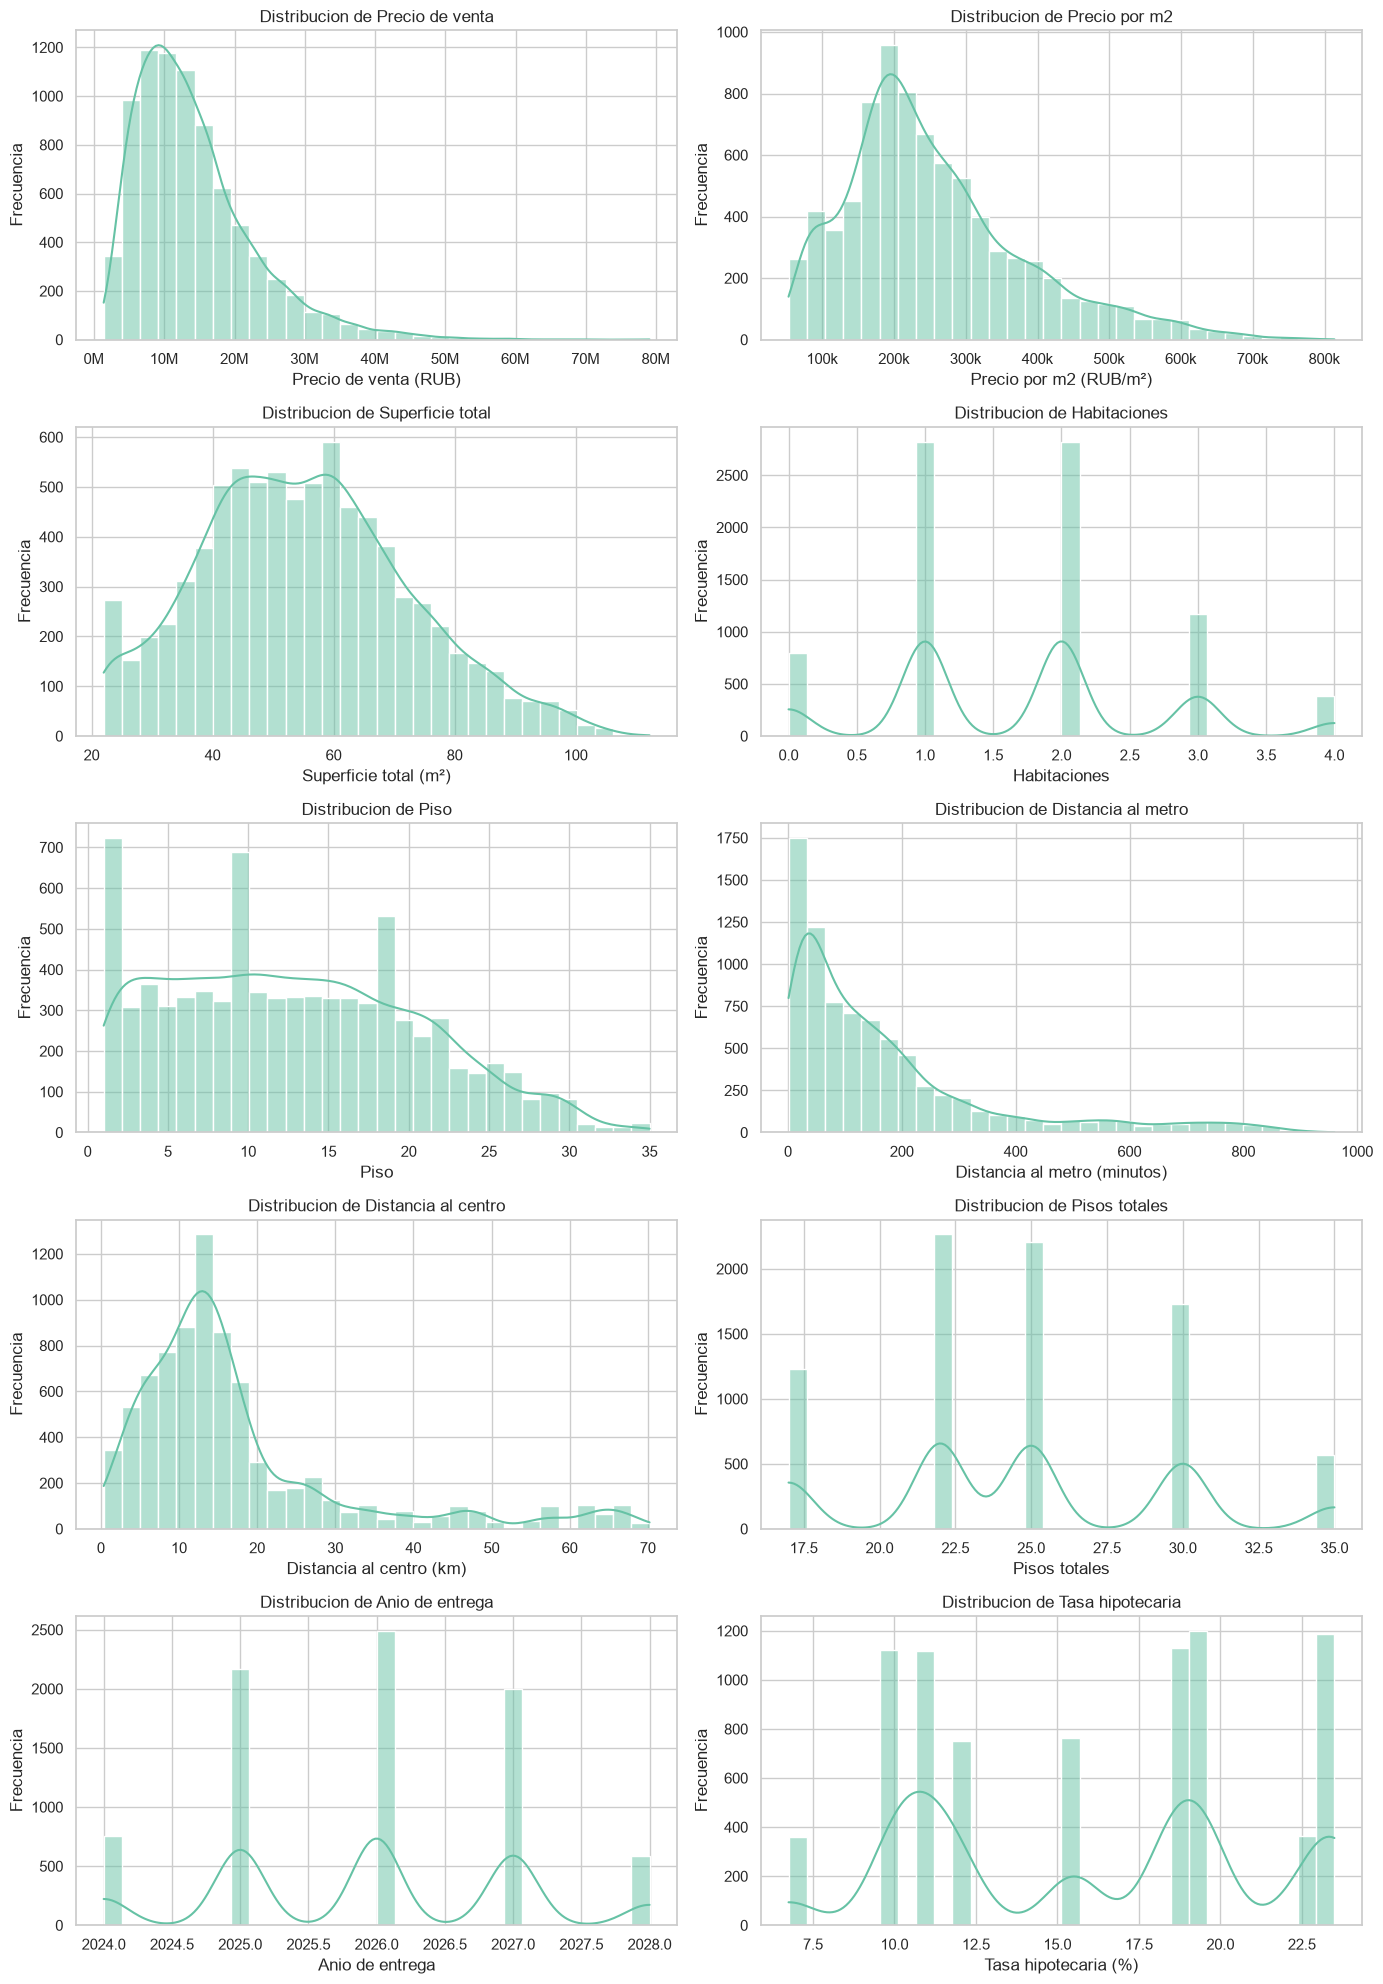

In [11]:
plot_histogramas(CONFIG["histogram_cols"])


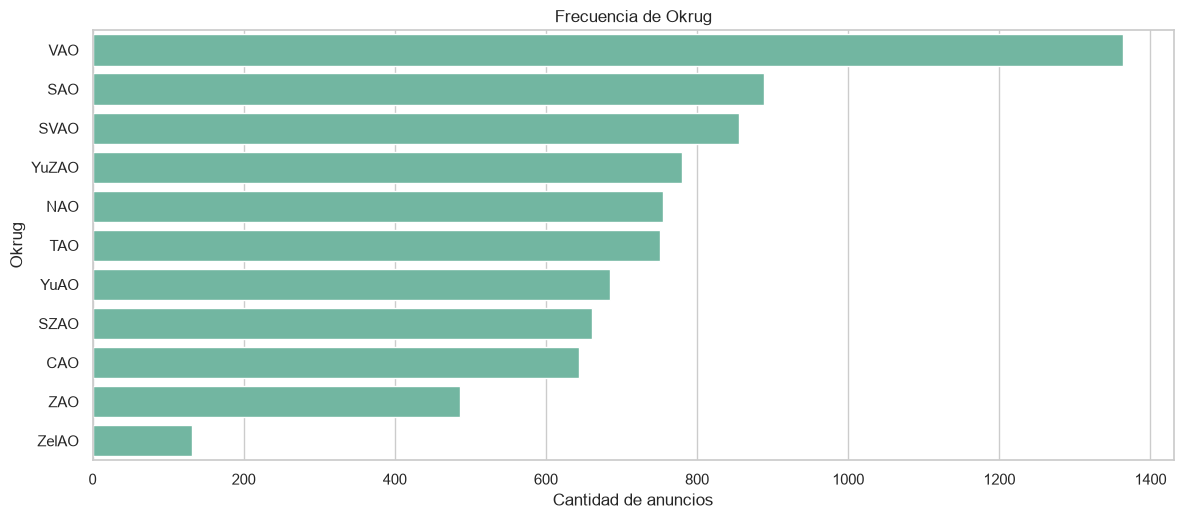

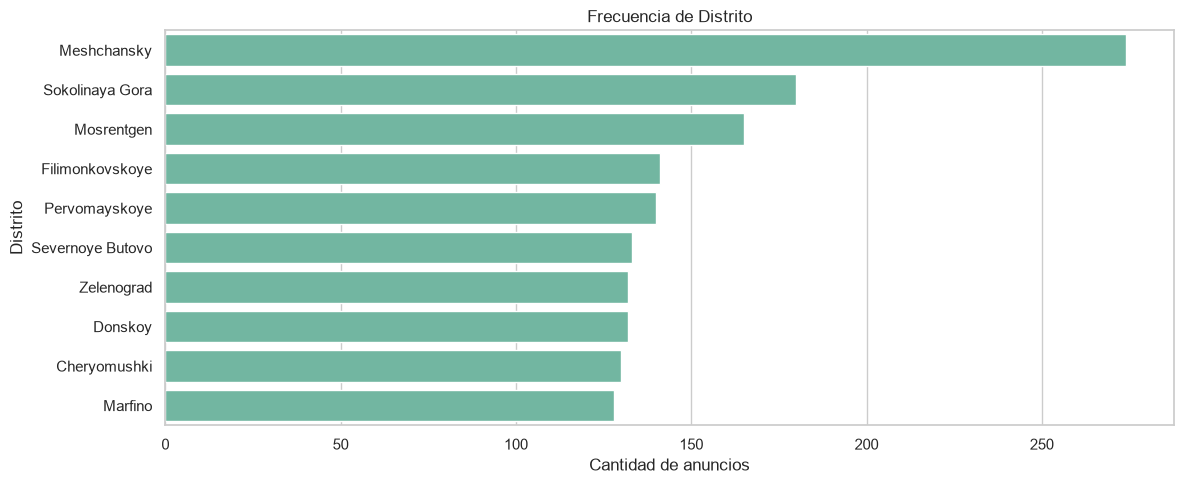

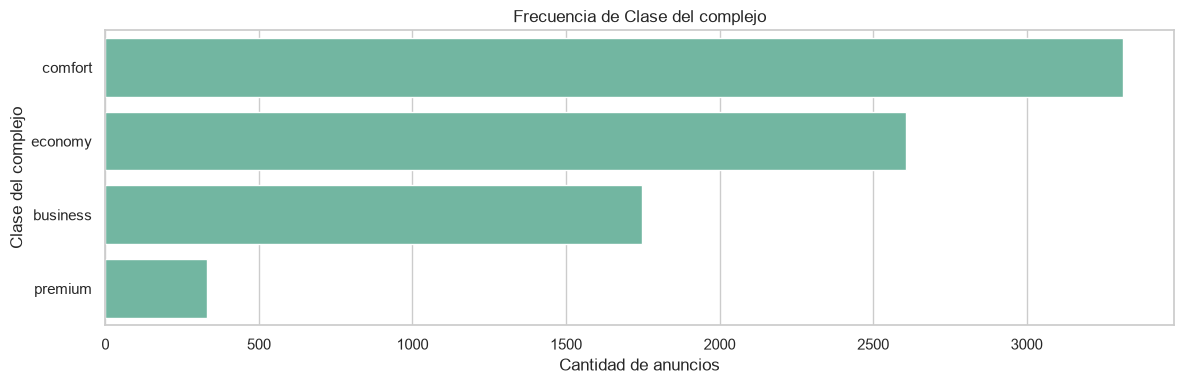

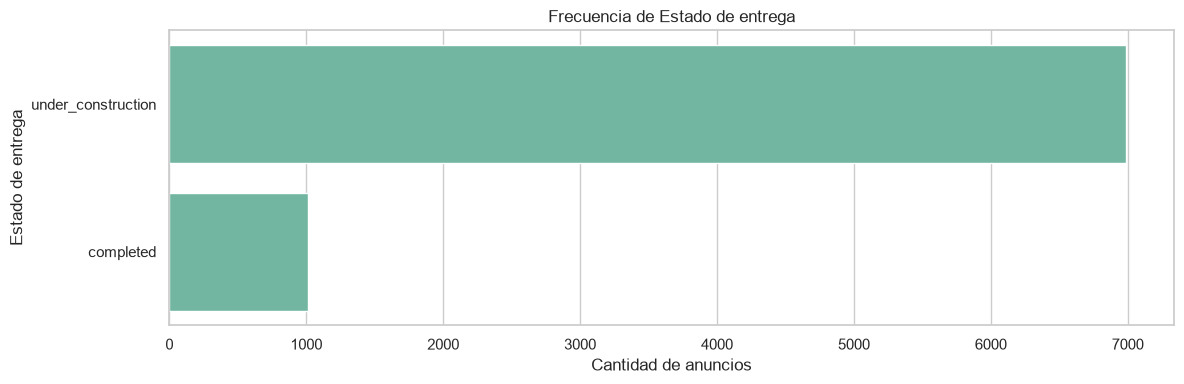

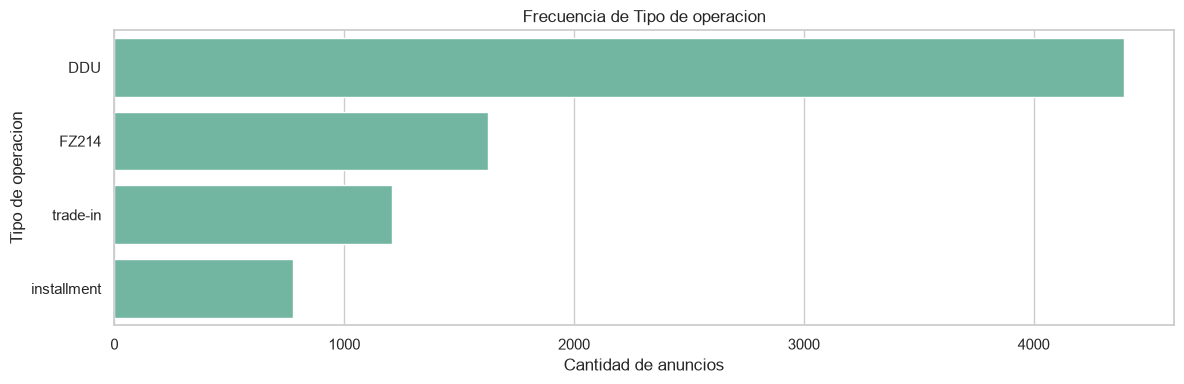

In [12]:
for item in CONFIG["bar_cols"]:
    plot_barras(item["col"], top_n=item.get("top_n"))


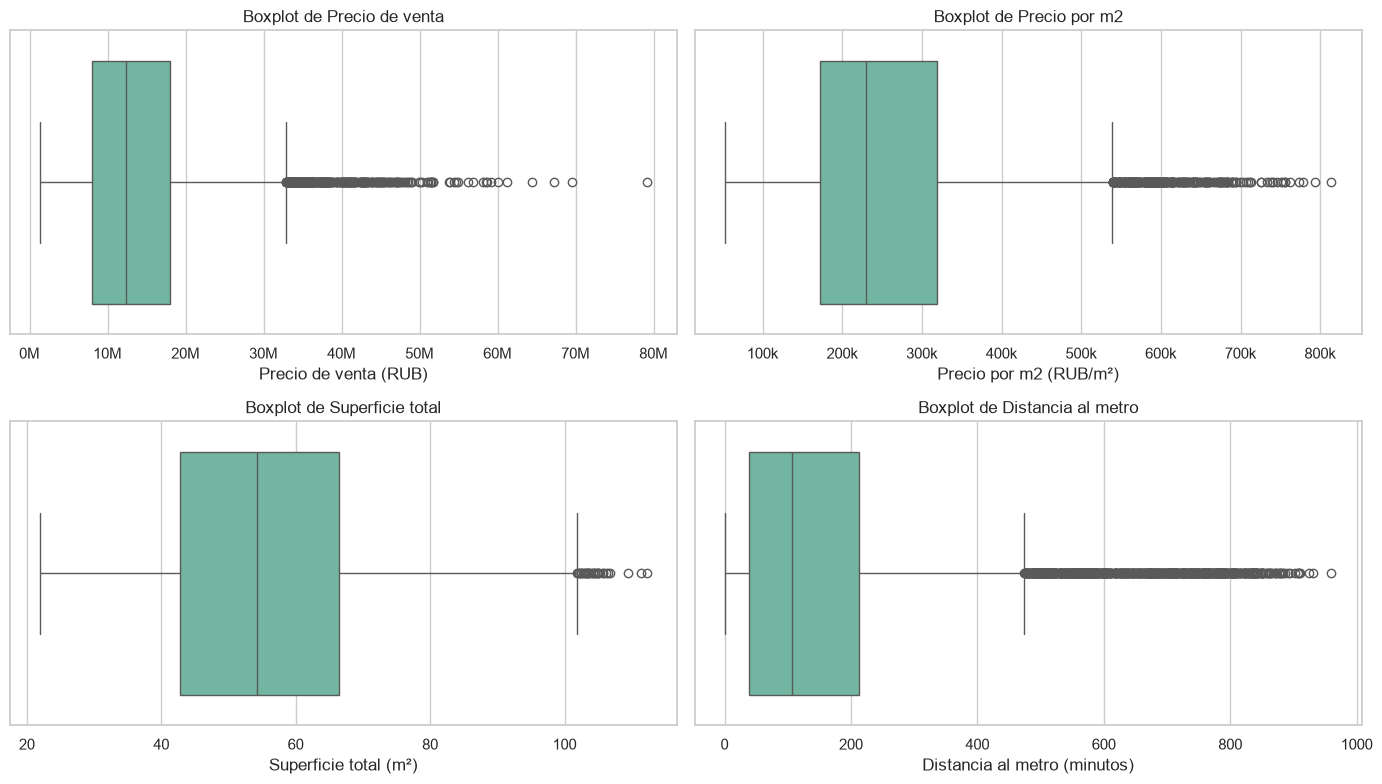

In [13]:
plot_boxplots_numericos(CONFIG["box_numeric_cols"])


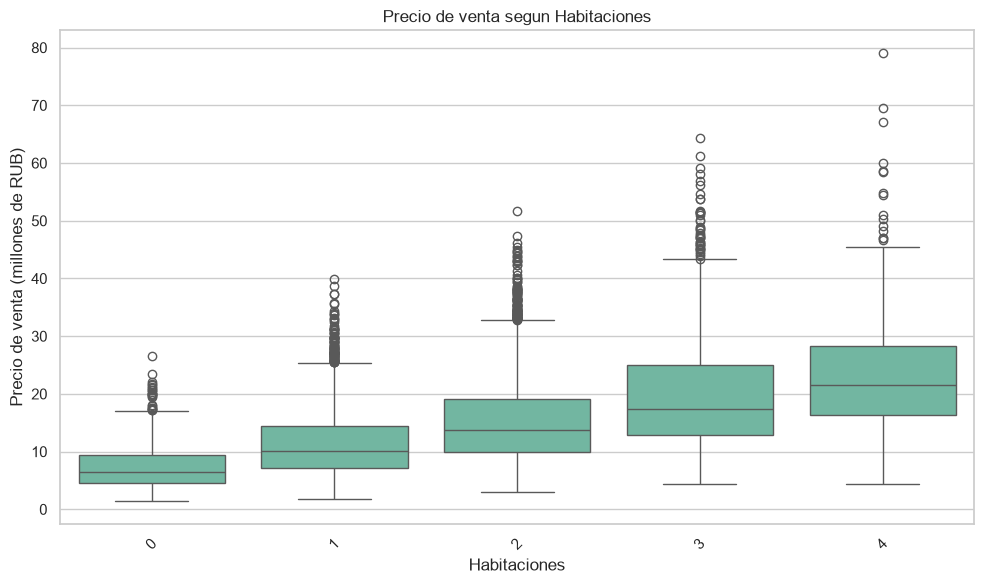

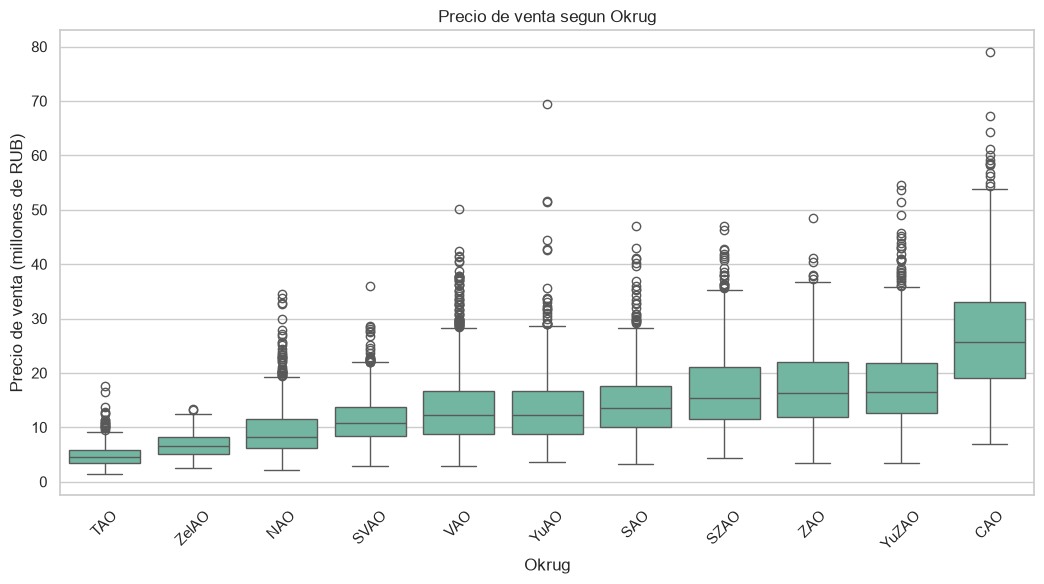

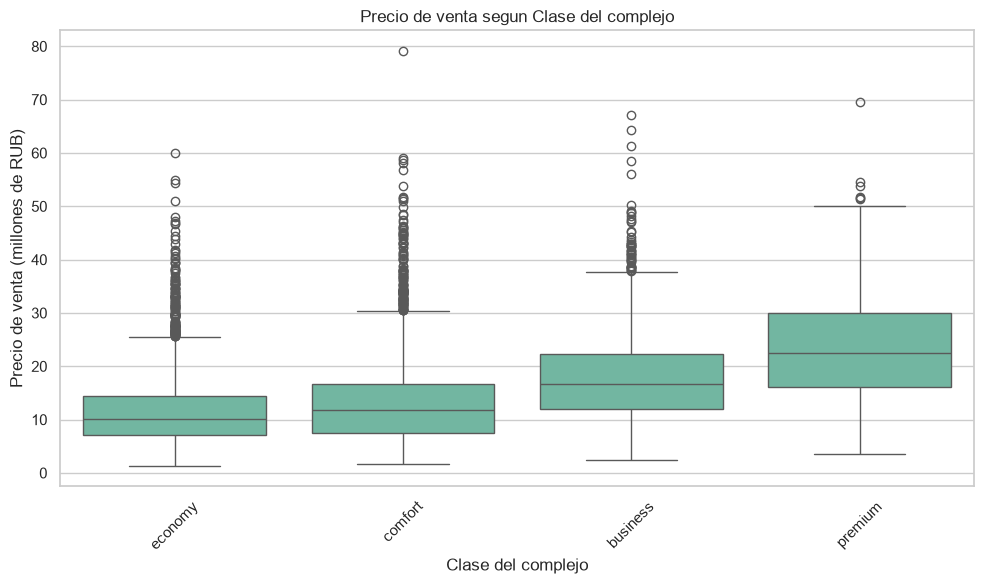

In [14]:
for item in CONFIG["price_category_cols"]:
    plot_precio_por_categoria(
        item["col"],
        top_n=item.get("top_n"),
        sort_numeric=item.get("sort_numeric", False),
    )


<a id="etapa-2-integracion-datos-auxiliares"></a>

## Etapa 2. Integracion de datos auxiliares

[Volver al indice](#indice)

En esta etapa se agregan variables externas utiles para el analisis posterior de venta de propiedades nuevas. Se trabaja siempre con copias enriquecidas del DataFrame de ventas para preservar `df` como dataset original cargado en el EDA.


<a id="join-district-prices"></a>

### Join con `district_prices_monthly.csv`

[Volver al indice](#indice)

Objetivo: incorporar precios mensuales de referencia, variaciones mensuales, volumen de publicaciones y tasas financieras por distrito.

Claves utilizadas:

- `date_posted` se convierte a fecha valida en una copia del dataset de ventas.
- A partir de esa fecha se crea `year_month` con formato `YYYY-MM`.
- El LEFT JOIN se realiza por `year_month`, `district` y `okrug`.

Antes del join se valida que `district_prices_monthly.csv` tenga una sola fila por combinacion `year_month`, `district` y `okrug`. Se excluyen columnas especificas de alquiler.


In [15]:
from pathlib import Path
import pandas as pd
from IPython.display import display

df_venta_original_shape = df.shape
df_venta_original_columns = df.columns.tolist()

district_prices_path = encontrar_archivo_data("district_prices_monthly.csv")
district_prices = pd.read_csv(district_prices_path)

district_join_keys = ["year_month", "district", "okrug"]
district_sales_columns = [
    "secondary_price_per_sqm",
    "newbuild_price_per_sqm",
    "secondary_mom_change_pct",
    "newbuild_mom_change_pct",
    "n_listings_secondary",
    "n_listings_newbuild",
    "cbr_key_rate_pct",
    "avg_mortgage_rate_pct",
]

duplicated_district_keys = int(district_prices.duplicated(district_join_keys).sum())
district_key_validation = pd.DataFrame(
    {
        "validacion": ["Filas duplicadas por year_month, district y okrug"],
        "resultado": [duplicated_district_keys],
    }
)
display(district_key_validation)

if duplicated_district_keys > 0:
    display(
        district_prices.loc[
            district_prices.duplicated(district_join_keys, keep=False),
            district_join_keys,
        ].sort_values(district_join_keys).head(20)
    )
    raise ValueError("La clave del dataset district_prices_monthly.csv no es unica.")

district_prices_sales = district_prices[district_join_keys + district_sales_columns].copy()

df_venta_district_prices = df.copy()
df_venta_district_prices["date_posted_dt"] = pd.to_datetime(
    df_venta_district_prices["date_posted"],
    errors="coerce",
)
df_venta_district_prices["year_month"] = df_venta_district_prices["date_posted_dt"].dt.strftime("%Y-%m")

df_venta_district_prices = df_venta_district_prices.merge(
    district_prices_sales,
    how="left",
    on=district_join_keys,
    indicator="_merge_district_prices",
    validate="many_to_one",
)

district_match_summary = (
    df_venta_district_prices["_merge_district_prices"]
    .value_counts(dropna=False)
    .rename_axis("resultado_join")
    .reset_index(name="registros")
)
district_match_summary["porcentaje"] = (
    district_match_summary["registros"] / len(df_venta_district_prices) * 100
)

district_dimensions = pd.DataFrame(
    {
        "dataframe": ["df original", "df_venta_district_prices"],
        "registros": [df_venta_original_shape[0], df_venta_district_prices.shape[0]],
        "columnas": [df_venta_original_shape[1], df_venta_district_prices.shape[1]],
    }
)

district_added_columns = [
    "date_posted_dt",
    "year_month",
    *district_sales_columns,
    "_merge_district_prices",
]
district_nulls_added = (
    df_venta_district_prices[district_sales_columns]
    .isna()
    .sum()
    .rename_axis("columna_agregada")
    .reset_index(name="valores_nulos")
)
district_nulls_added["porcentaje_nulos"] = (
    district_nulls_added["valores_nulos"] / len(df_venta_district_prices) * 100
)

print(f"Dataset auxiliar cargado: {district_prices_path}")
print("Dimensiones antes y despues del LEFT JOIN")
display(district_dimensions)

print("Columnas agregadas o generadas")
display(pd.DataFrame({"columna": district_added_columns}))

print("Coincidencias del LEFT JOIN")
display(district_match_summary.style.format({"porcentaje": "{:.2f}%"}))

print("Registros sin correspondencia")
display(
    df_venta_district_prices.loc[
        df_venta_district_prices["_merge_district_prices"] == "left_only",
        ["id", "date_posted", "year_month", "district", "okrug"],
    ].head(10)
)

print("Valores nulos en variables incorporadas")
display(district_nulls_added.style.format({"porcentaje_nulos": "{:.2f}%"}))


,validacion,resultado
0,"Filas duplicadas por year_month, district y okrug",0


Dataset auxiliar cargado: c:\Users\mglon\OneDrive\Desktop\UNIVERSIDAD\Introduccion al analisis de datos\MOSCOW DATASET\Moscow_EDA\Data\district_prices_monthly.csv
Dimensiones antes y despues del LEFT JOIN


,dataframe,registros,columnas
0,df original,8000,25
1,df_venta_district_prices,8000,36


Columnas agregadas o generadas


,columna
0,date_posted_dt
1,year_month
2,secondary_price_per_sqm
3,newbuild_price_per_sqm
4,secondary_mom_change_pct
5,newbuild_mom_change_pct
6,n_listings_secondary
7,n_listings_newbuild
8,cbr_key_rate_pct
9,avg_mortgage_rate_pct


...

,resultado_join,registros,porcentaje
0,both,8000,100.00%
1,left_only,0,0.00%
2,right_only,0,0.00%


Registros sin correspondencia


,id,date_posted,year_month,district,okrug


Valores nulos en variables incorporadas


,columna_agregada,valores_nulos,porcentaje_nulos
0,secondary_price_per_sqm,0,0.00%
1,newbuild_price_per_sqm,0,0.00%
2,secondary_mom_change_pct,0,0.00%
3,newbuild_mom_change_pct,0,0.00%
4,n_listings_secondary,0,0.00%
5,n_listings_newbuild,0,0.00%
6,cbr_key_rate_pct,0,0.00%
7,avg_mortgage_rate_pct,0,0.00%


<a id="join-metro-stations"></a>

### Join con `metro_stations.csv`

[Volver al indice](#indice)

Objetivo: incorporar informacion descriptiva de la estacion de metro asociada al anuncio.

Claves utilizadas:

- `metro_station` del dataset de ventas se relaciona con `station_name` del dataset auxiliar.
- `metro_line` del dataset de ventas se relaciona con `line` del dataset auxiliar.

Antes del join se valida que `metro_stations.csv` tenga una sola fila por combinacion `station_name` y `line`. Las columnas `lat`, `lon` y `to_center_km` del dataset auxiliar se renombran para conservar las variables originales de la propiedad.


In [16]:
metro_stations_path = encontrar_archivo_data("metro_stations.csv")
metro_stations = pd.read_csv(metro_stations_path)

metro_aux_keys = ["station_name", "line"]
duplicated_metro_keys = int(metro_stations.duplicated(metro_aux_keys).sum())
metro_key_validation = pd.DataFrame(
    {
        "validacion": ["Filas duplicadas por station_name y line"],
        "resultado": [duplicated_metro_keys],
    }
)
display(metro_key_validation)

if duplicated_metro_keys > 0:
    display(
        metro_stations.loc[
            metro_stations.duplicated(metro_aux_keys, keep=False),
            metro_aux_keys,
        ].sort_values(metro_aux_keys).head(20)
    )
    raise ValueError("La clave del dataset metro_stations.csv no es unica.")

metro_stations_sales = (
    metro_stations[
        ["station_name", "line", "lat", "lon", "year_opened", "to_center_km"]
    ]
    .rename(
        columns={
            "station_name": "metro_station",
            "line": "metro_line",
            "lat": "metro_lat",
            "lon": "metro_lon",
            "year_opened": "metro_year_opened",
            "to_center_km": "metro_to_center_km",
        }
    )
    .copy()
)

metro_join_keys = ["metro_station", "metro_line"]
metro_added_columns = ["metro_lat", "metro_lon", "metro_year_opened", "metro_to_center_km"]

df_venta_enriquecido = df_venta_district_prices.merge(
    metro_stations_sales,
    how="left",
    on=metro_join_keys,
    indicator="_merge_metro_stations",
    validate="many_to_one",
)

metro_match_summary = (
    df_venta_enriquecido["_merge_metro_stations"]
    .value_counts(dropna=False)
    .rename_axis("resultado_join")
    .reset_index(name="registros")
)
metro_match_summary["porcentaje"] = (
    metro_match_summary["registros"] / len(df_venta_enriquecido) * 100
)

metro_dimensions = pd.DataFrame(
    {
        "dataframe": ["df_venta_district_prices", "df_venta_enriquecido"],
        "registros": [df_venta_district_prices.shape[0], df_venta_enriquecido.shape[0]],
        "columnas": [df_venta_district_prices.shape[1], df_venta_enriquecido.shape[1]],
    }
)

metro_nulls_added = (
    df_venta_enriquecido[metro_added_columns]
    .isna()
    .sum()
    .rename_axis("columna_agregada")
    .reset_index(name="valores_nulos")
)
metro_nulls_added["porcentaje_nulos"] = (
    metro_nulls_added["valores_nulos"] / len(df_venta_enriquecido) * 100
)

print(f"Dataset auxiliar cargado: {metro_stations_path}")
print("Dimensiones antes y despues del LEFT JOIN")
display(metro_dimensions)

print("Columnas agregadas")
display(pd.DataFrame({"columna": [*metro_added_columns, "_merge_metro_stations"]}))

print("Coincidencias del LEFT JOIN")
display(metro_match_summary.style.format({"porcentaje": "{:.2f}%"}))

print("Registros sin correspondencia")
display(
    df_venta_enriquecido.loc[
        df_venta_enriquecido["_merge_metro_stations"] == "left_only",
        ["id", "metro_station", "metro_line"],
    ].head(10)
)

print("Valores nulos en variables incorporadas")
display(metro_nulls_added.style.format({"porcentaje_nulos": "{:.2f}%"}))


,validacion,resultado
0,Filas duplicadas por station_name y line,0


Dataset auxiliar cargado: c:\Users\mglon\OneDrive\Desktop\UNIVERSIDAD\Introduccion al analisis de datos\MOSCOW DATASET\Moscow_EDA\Data\metro_stations.csv
Dimensiones antes y despues del LEFT JOIN


,dataframe,registros,columnas
0,df_venta_district_prices,8000,36
1,df_venta_enriquecido,8000,41


Columnas agregadas


,columna
0,metro_lat
1,metro_lon
2,metro_year_opened
3,metro_to_center_km
4,_merge_metro_stations


...

,resultado_join,registros,porcentaje
0,both,8000,100.00%
1,left_only,0,0.00%
2,right_only,0,0.00%


Registros sin correspondencia


,id,metro_station,metro_line


Valores nulos en variables incorporadas


,columna_agregada,valores_nulos,porcentaje_nulos
0,metro_lat,0,0.00%
1,metro_lon,0,0.00%
2,metro_year_opened,0,0.00%
3,metro_to_center_km,0,0.00%


<a id="descripcion-columnas-enriquecido"></a>

### Descripción de las columnas del dataframe enriquecido

[Volver al indice](#indice)

Tras los dos LEFT JOIN, `df_venta_enriquecido` conserva los 8.000 anuncios y tiene **41 columnas**: las 25 originales y 16 columnas agregadas o generadas durante la integración. Las originales, descritas en la sección 1.1, contienen los identificadores, las características de la propiedad y del complejo, la ubicación, los precios del anuncio y las condiciones de financiación.

Las columnas nuevas permiten relacionar cada anuncio con el contexto del mercado en su distrito y mes de publicación, y con las características de la estación de metro asociada:

| Columna | Descripción breve |
| --- | --- |
| `date_posted_dt` | Fecha de publicación convertida a tipo fecha para trabajar con el tiempo. |
| `year_month` | Año y mes de publicación (`YYYY-MM`), utilizado junto con `district` y `okrug` como clave del join de precios. |
| `secondary_price_per_sqm` | Precio de referencia por m² de propiedades usadas para el distrito y mes del anuncio, en RUB/m². |
| `newbuild_price_per_sqm` | Precio de referencia por m² de propiedades nuevas para el distrito y mes del anuncio, en RUB/m². |
| `secondary_mom_change_pct` | Variación porcentual del precio de referencia de propiedades usadas respecto del mes anterior. |
| `newbuild_mom_change_pct` | Variación porcentual del precio de referencia de propiedades nuevas respecto del mes anterior. |
| `n_listings_secondary` | Cantidad de anuncios de propiedades usadas registrados para el distrito y mes. |
| `n_listings_newbuild` | Cantidad de anuncios de propiedades nuevas registrados para el distrito y mes. |
| `cbr_key_rate_pct` | Tasa de referencia del Banco Central de Rusia correspondiente al mes, en porcentaje. |
| `avg_mortgage_rate_pct` | Tasa hipotecaria promedio correspondiente al mes, en porcentaje. |
| `metro_lat` | Latitud de la estación de metro asociada al anuncio, en grados. |
| `metro_lon` | Longitud de la estación de metro asociada al anuncio, en grados. |
| `metro_year_opened` | Año de inauguración de la estación de metro. |
| `metro_to_center_km` | Distancia de la estación de metro al centro de Moscú, en kilómetros. |
| `_merge_district_prices` | Indicador de correspondencia del join con los precios mensuales: `both` indica coincidencia y `left_only`, ausencia de coincidencia. |
| `_merge_metro_stations` | Indicador de correspondencia del join con las estaciones: `both` indica coincidencia y `left_only`, ausencia de coincidencia. |

`price_per_sqm` representa el precio por m² de cada anuncio; los precios incorporados son referencias del mercado para su distrito y mes. Asimismo, `lat`, `lon` y `to_center_km` describen la propiedad, mientras que `metro_lat`, `metro_lon` y `metro_to_center_km` describen la estación. Los indicadores `_merge_` sirven para controlar la calidad de las uniones.


<a id="etapa-3-validacion-integraciones"></a>

## Etapa 3. Validacion final de los joins

[Volver al indice](#indice)

Esta seccion comprueba que los LEFT JOINs no alteraron el universo original de propiedades, que los identificadores se conservan, que no se generaron duplicados y que las correspondencias con los datasets auxiliares son completas.


In [17]:
expected_records_by_dataset = {
    "new_builds.csv": 8000,
    "secondary_market.csv": 50000,
}
expected_records = expected_records_by_dataset.get(DATASET_FILE, df.shape[0])

id_column = "id"
district_unmatched_count = int((df_venta_district_prices["_merge_district_prices"] == "left_only").sum())
metro_unmatched_count = int((df_venta_enriquecido["_merge_metro_stations"] == "left_only").sum())

original_values_preserved = (
    df_venta_enriquecido[df_venta_original_columns]
    .reset_index(drop=True)
    .equals(df.reset_index(drop=True))
)

final_duplicate_rows = int(df_venta_enriquecido.duplicated().sum())
final_duplicate_ids = int(df_venta_enriquecido[id_column].duplicated().sum())

validation_checks = pd.DataFrame(
    [
        {
            "validacion": "Cantidad esperada de registros en df original",
            "resultado": df.shape[0] == expected_records,
            "detalle": f"{df.shape[0]:,} registros. Esperado: {expected_records:,}.",
        },
        {
            "validacion": "Cantidad de registros luego del join con district_prices_monthly",
            "resultado": df_venta_district_prices.shape[0] == df.shape[0],
            "detalle": f"{df_venta_district_prices.shape[0]:,} registros.",
        },
        {
            "validacion": "Cantidad de registros luego del join con metro_stations",
            "resultado": df_venta_enriquecido.shape[0] == df.shape[0],
            "detalle": f"{df_venta_enriquecido.shape[0]:,} registros.",
        },
        {
            "validacion": "El identificador original id sigue siendo unico",
            "resultado": df[id_column].is_unique and df_venta_enriquecido[id_column].is_unique,
            "detalle": f"Duplicados de id en df final: {final_duplicate_ids:,}.",
        },
        {
            "validacion": "Los joins no generaron filas duplicadas completas",
            "resultado": final_duplicate_rows == 0,
            "detalle": f"Filas duplicadas completas en df final: {final_duplicate_rows:,}.",
        },
        {
            "validacion": "Todas las propiedades tienen correspondencia en district_prices_monthly",
            "resultado": district_unmatched_count == 0,
            "detalle": f"Sin correspondencia: {district_unmatched_count:,}.",
        },
        {
            "validacion": "Todas las propiedades tienen correspondencia en metro_stations",
            "resultado": metro_unmatched_count == 0,
            "detalle": f"Sin correspondencia: {metro_unmatched_count:,}.",
        },
        {
            "validacion": "Las columnas originales conservan sus valores",
            "resultado": original_values_preserved,
            "detalle": f"Columnas comparadas: {len(df_venta_original_columns):,}.",
        },
    ]
)

display(validation_checks)

identifier_validation = pd.DataFrame(
    [
        {
            "identificador": col,
            "unico_en_df_original": df[col].is_unique,
            "unico_en_df_final": df_venta_enriquecido[col].is_unique,
            "valores_unicos_original": df[col].nunique(dropna=True),
            "valores_unicos_final": df_venta_enriquecido[col].nunique(dropna=True),
            "observacion": "Identificador unico de propiedad"
            if col == "id"
            else "Identificador descriptivo. Puede repetirse por diseno del dataset.",
        }
        for col in [c for c in CONFIG.get("identifier_cols", []) if c in df.columns]
    ]
)
display(identifier_validation)


,validacion,resultado,detalle
0,Cantidad esperada de registros en df original,True,"8,000 registros. Esperado: 8,000."
1,Cantidad de registros luego del join con distr...,True,"8,000 registros."
2,Cantidad de registros luego del join con metro...,True,"8,000 registros."
3,El identificador original id sigue siendo unico,True,Duplicados de id en df final: 0.
4,Los joins no generaron filas duplicadas completas,True,Filas duplicadas completas en df final: 0.
5,Todas las propiedades tienen correspondencia e...,True,Sin correspondencia: 0.
6,Todas las propiedades tienen correspondencia e...,True,Sin correspondencia: 0.
7,Las columnas originales conservan sus valores,True,Columnas comparadas: 25.


,identificador,unico_en_df_original,unico_en_df_final,valores_unicos_original,valores_unicos_final,observacion
0,id,True,True,8000,8000,Identificador unico de propiedad
1,complex_id,False,False,250,250,Identificador descriptivo. Puede repetirse por...


In [18]:
def tipo_esperado_ok(serie, tipo_esperado):
    if tipo_esperado == "datetime":
        return pd.api.types.is_datetime64_any_dtype(serie)
    if tipo_esperado == "numeric":
        return pd.api.types.is_numeric_dtype(serie)
    if tipo_esperado == "text":
        return pd.api.types.is_object_dtype(serie) or pd.api.types.is_string_dtype(serie)
    return False

expected_new_column_types = {
    "date_posted_dt": "datetime",
    "year_month": "text",
    "secondary_price_per_sqm": "numeric",
    "newbuild_price_per_sqm": "numeric",
    "secondary_mom_change_pct": "numeric",
    "newbuild_mom_change_pct": "numeric",
    "n_listings_secondary": "numeric",
    "n_listings_newbuild": "numeric",
    "cbr_key_rate_pct": "numeric",
    "avg_mortgage_rate_pct": "numeric",
    "metro_lat": "numeric",
    "metro_lon": "numeric",
    "metro_year_opened": "numeric",
    "metro_to_center_km": "numeric",
}

type_validation = pd.DataFrame(
    [
        {
            "columna": col,
            "tipo_esperado": expected_type,
            "tipo_observado": str(df_venta_enriquecido[col].dtype),
            "cumple": tipo_esperado_ok(df_venta_enriquecido[col], expected_type),
        }
        for col, expected_type in expected_new_column_types.items()
        if col in df_venta_enriquecido.columns
    ]
)
display(type_validation)


,columna,tipo_esperado,tipo_observado,cumple
0,date_posted_dt,datetime,datetime64[us],True
1,year_month,text,str,True
2,secondary_price_per_sqm,numeric,int64,True
3,newbuild_price_per_sqm,numeric,int64,True
4,secondary_mom_change_pct,numeric,float64,True
5,newbuild_mom_change_pct,numeric,float64,True
6,n_listings_secondary,numeric,int64,True
7,n_listings_newbuild,numeric,int64,True
8,cbr_key_rate_pct,numeric,float64,True
9,avg_mortgage_rate_pct,numeric,float64,True


In [19]:
district_aux_nulls = (
    district_prices_sales[district_sales_columns]
    .isna()
    .sum()
    .rename("nulos_en_auxiliar")
)
district_matched_mask = df_venta_district_prices["_merge_district_prices"] == "both"
district_nulls_matched = (
    df_venta_district_prices.loc[district_matched_mask, district_sales_columns]
    .isna()
    .sum()
    .rename("nulos_en_final_con_match")
)
district_nulls_unmatched = (
    df_venta_district_prices.loc[~district_matched_mask, district_sales_columns]
    .isna()
    .sum()
    .rename("nulos_en_final_sin_match")
)

district_null_origin = (
    pd.concat([district_aux_nulls, district_nulls_matched, district_nulls_unmatched], axis=1)
    .reset_index()
    .rename(columns={"index": "columna"})
)
district_null_origin["interpretacion"] = district_null_origin.apply(
    lambda row: "Nulos heredados del auxiliar o propios del indicador"
    if row["nulos_en_final_con_match"] > 0 and row["nulos_en_final_sin_match"] == 0
    else "Sin nulos en propiedades con correspondencia"
    if row["nulos_en_final_con_match"] == 0 and row["nulos_en_final_sin_match"] == 0
    else "Revisar posibles nulos asociados a falta de correspondencia",
    axis=1,
)

metro_aux_nulls = (
    metro_stations_sales[metro_added_columns]
    .isna()
    .sum()
    .rename("nulos_en_auxiliar")
)
metro_matched_mask = df_venta_enriquecido["_merge_metro_stations"] == "both"
metro_nulls_matched = (
    df_venta_enriquecido.loc[metro_matched_mask, metro_added_columns]
    .isna()
    .sum()
    .rename("nulos_en_final_con_match")
)
metro_nulls_unmatched = (
    df_venta_enriquecido.loc[~metro_matched_mask, metro_added_columns]
    .isna()
    .sum()
    .rename("nulos_en_final_sin_match")
)

metro_null_origin = (
    pd.concat([metro_aux_nulls, metro_nulls_matched, metro_nulls_unmatched], axis=1)
    .reset_index()
    .rename(columns={"index": "columna"})
)
metro_null_origin["interpretacion"] = metro_null_origin.apply(
    lambda row: "Nulos heredados del auxiliar"
    if row["nulos_en_final_con_match"] > 0 and row["nulos_en_final_sin_match"] == 0
    else "Sin nulos en propiedades con correspondencia"
    if row["nulos_en_final_con_match"] == 0 and row["nulos_en_final_sin_match"] == 0
    else "Revisar posibles nulos asociados a falta de correspondencia",
    axis=1,
)

print("Origen de nulos en columnas incorporadas desde district_prices_monthly.csv")
display(district_null_origin)

print("Origen de nulos en columnas incorporadas desde metro_stations.csv")
display(metro_null_origin)

print(
    "Nota: los porcentajes de variacion mensual del auxiliar de precios pueden tener nulos legitimos en enero de 2020 por falta de un mes anterior."
)


Origen de nulos en columnas incorporadas desde district_prices_monthly.csv


,columna,nulos_en_auxiliar,nulos_en_final_con_match,nulos_en_final_sin_match,interpretacion
0,secondary_price_per_sqm,0,0,0,Sin nulos en propiedades con correspondencia
1,newbuild_price_per_sqm,0,0,0,Sin nulos en propiedades con correspondencia
2,secondary_mom_change_pct,129,0,0,Sin nulos en propiedades con correspondencia
3,newbuild_mom_change_pct,129,0,0,Sin nulos en propiedades con correspondencia
4,n_listings_secondary,0,0,0,Sin nulos en propiedades con correspondencia
5,n_listings_newbuild,0,0,0,Sin nulos en propiedades con correspondencia
6,cbr_key_rate_pct,0,0,0,Sin nulos en propiedades con correspondencia
7,avg_mortgage_rate_pct,0,0,0,Sin nulos en propiedades con correspondencia


Origen de nulos en columnas incorporadas desde metro_stations.csv


,columna,nulos_en_auxiliar,nulos_en_final_con_match,nulos_en_final_sin_match,interpretacion
0,metro_lat,0,0,0,Sin nulos en propiedades con correspondencia
1,metro_lon,0,0,0,Sin nulos en propiedades con correspondencia
2,metro_year_opened,0,0,0,Sin nulos en propiedades con correspondencia
3,metro_to_center_km,0,0,0,Sin nulos en propiedades con correspondencia


Nota: los porcentajes de variacion mensual del auxiliar de precios pueden tener nulos legitimos en enero de 2020 por falta de un mes anterior.


In [20]:
final_sample_columns = [
    "id",
    "date_posted",
    "year_month",
    "district",
    "okrug",
    "metro_station",
    "metro_line",
    "price_rub",
    "price_per_sqm",
    "secondary_price_per_sqm",
    "newbuild_price_per_sqm",
    "secondary_mom_change_pct",
    "newbuild_mom_change_pct",
    "cbr_key_rate_pct",
    "avg_mortgage_rate_pct",
    "metro_lat",
    "metro_lon",
    "metro_year_opened",
    "metro_to_center_km",
]
final_sample_columns = [col for col in final_sample_columns if col in df_venta_enriquecido.columns]

display(df_venta_enriquecido[final_sample_columns].head(10))


,id,date_posted,year_month,district,okrug,metro_station,metro_line,price_rub,price_per_sqm,secondary_price_per_sqm,newbuild_price_per_sqm,secondary_mom_change_pct,newbuild_mom_change_pct,cbr_key_rate_pct,avg_mortgage_rate_pct,metro_lat,metro_lon,metro_year_opened,metro_to_center_km
0,N000001,2023-11-22,2023-11,Sosenskoye,NAO,Kutuzovskaya,Filyovskaya,22075000,247200,225600,259000,3.46,13.09,13.00,15.50,55.74,37.53,1958,5.65
1,N000002,2021-07-08,2021-07,Novo-Peredelkino,ZAO,Polyanka,Serpukhovsko-Timiryazevskaya,22445000,295700,258900,297500,2.86,5.83,8.50,11.00,55.74,37.62,1986,1.80
2,N000003,2022-02-20,2022-02,Brateyevo,YuAO,Mayakovskaya,Zamoskvoretskaya,7075000,145600,227100,252300,3.58,5.69,20.00,22.50,55.77,37.60,1938,2.36
3,N000004,2025-03-23,2025-03,Voronovskoye,TAO,Krasnopresnenskaya,Koltsevaya,3011000,82500,116700,127200,-0.15,3.44,21.00,23.50,55.76,37.58,1954,2.76
4,N000005,2022-08-05,2022-08,Krasnopakhorskoye,TAO,Yugo-Zapadnaya,Sokolnicheskaya,4420000,84700,111000,122700,-0.27,1.92,9.50,12.00,55.66,37.48,1963,13.23
5,N000006,2022-05-23,2022-05,Zelenograd,ZelAO,Sokol,Zamoskvoretskaya,8169000,107900,164300,172300,0.10,0.17,9.50,12.00,55.80,37.52,1938,8.72
6,N000007,2023-06-14,2023-06,Zapadnoye Degunino,SAO,Rizhskaya,Kaluzhsko-Rizhskaya,11909000,268800,269300,291400,1.63,0.56,7.50,10.00,55.79,37.64,1958,4.33
7,N000008,2024-08-31,2024-08,Strogino,SZAO,Delovoy Tsentr,MCC,36447000,453300,420100,459600,-4.44,-2.59,16.00,18.50,55.75,37.54,2014,5.37
8,N000009,2025-04-23,2025-04,Koptevo,SAO,Rechnoy Vokzal,Zamoskvoretskaya,7502000,226000,304100,328300,4.64,1.89,21.00,23.50,55.85,37.48,1964,14.02
9,N000010,2025-05-21,2025-05,Koptevo,SAO,Arbatskaya (F),Filyovskaya,9504000,197200,302600,323100,-0.50,-1.58,21.00,23.50,55.75,37.60,1935,1.10


<a id="resultados-integracion"></a>

## Resultados de integracion

[Volver al indice](#indice)

La tabla siguiente resume los dos joins realizados. Ambos se ejecutan como LEFT JOIN para conservar todas las propiedades del dataset original.


In [21]:
district_match_pct = (df_venta_district_prices["_merge_district_prices"] == "both").mean() * 100
metro_match_pct = (df_venta_enriquecido["_merge_metro_stations"] == "both").mean() * 100

resultados_integracion = pd.DataFrame(
    [
        {
            "dataset_auxiliar": "district_prices_monthly.csv",
            "tipo_join": "LEFT JOIN",
            "claves_union": "year_month derivado de date_posted, district, okrug",
            "registros_antes": df.shape[0],
            "registros_despues": df_venta_district_prices.shape[0],
            "columnas_nuevas": ", ".join(["date_posted_dt", "year_month", *district_sales_columns]),
            "porcentaje_coincidencias": district_match_pct,
            "observaciones_calidad": (
                "Clave auxiliar unica. No se incorporan columnas de alquiler. "
                "Se conserva el mes contemporaneo de date_posted sin desplazamientos. "
                "Las variaciones mensuales pueden contener nulos legitimos al inicio de la serie."
            ),
        },
        {
            "dataset_auxiliar": "metro_stations.csv",
            "tipo_join": "LEFT JOIN",
            "claves_union": "metro_station = station_name, metro_line = line",
            "registros_antes": df_venta_district_prices.shape[0],
            "registros_despues": df_venta_enriquecido.shape[0],
            "columnas_nuevas": ", ".join(metro_added_columns),
            "porcentaje_coincidencias": metro_match_pct,
            "observaciones_calidad": (
                "Clave auxiliar unica. Las coordenadas y distancia al centro de las propiedades no se reemplazan. "
                "Las variables de estacion se agregan con prefijo metro_."
            ),
        },
    ]
)

display(resultados_integracion.style.format({"porcentaje_coincidencias": "{:.2f}%"}))


,dataset_auxiliar,tipo_join,claves_union,registros_antes,registros_despues,columnas_nuevas,porcentaje_coincidencias,observaciones_calidad
0,district_prices_monthly.csv,LEFT JOIN,"year_month derivado de date_posted, district, okrug",8000,8000,"date_posted_dt, year_month, secondary_price_per_sqm, newbuild_price_per_sqm, secondary_mom_change_pct, newbuild_mom_change_pct, n_listings_secondary, n_listings_newbuild, cbr_key_rate_pct, avg_mortgage_rate_pct",100.00%,Clave auxiliar unica. No se incorporan columnas de alquiler. Se conserva el mes contemporaneo de date_posted sin desplazamientos. Las variaciones mensuales pueden contener nulos legitimos al inicio de la serie.
1,metro_stations.csv,LEFT JOIN,"metro_station = station_name, metro_line = line",8000,8000,"metro_lat, metro_lon, metro_year_opened, metro_to_center_km",100.00%,Clave auxiliar unica. Las coordenadas y distancia al centro de las propiedades no se reemplazan. Las variables de estacion se agregan con prefijo metro_.


### Aporte de los datasets auxiliares

`district_prices_monthly.csv` agrega contexto mensual del mercado por distrito y okrug: precios de referencia para propiedades usadas y nuevas, variaciones mensuales, volumen de anuncios y tasas financieras. En esta etapa se usa el mismo mes de `date_posted` para la union inicial. No se aplican desplazamientos temporales.

`metro_stations.csv` agrega informacion espacial y temporal de la estacion de metro asociada a cada anuncio: coordenadas de la estacion, año de inauguracion y distancia de la estacion al centro. Estas variables no reemplazan las coordenadas ni distancias originales de las propiedades.

Para futuros modelos predictivos sera necesario evaluar el riesgo de fuga de informacion de los indicadores mensuales contemporaneos, especialmente si el objetivo a predecir se observa dentro del mismo mes de publicacion. En este notebook no se aplica limpieza adicional, tratamiento de outliers, escalado, seleccion de features ni entrenamiento de modelos. Tampoco se incorpora analisis del dataset `rentals.csv`.


<a id="resumen-final-dataframe"></a>

## Resumen final del dataframe enriquecido

[Volver al indice](#indice)

Esta tabla resume todas las columnas de `df_venta_enriquecido`, incluidas las originales y las incorporadas por los joins. `ID` enumera las columnas desde 1 y el ejemplo corresponde al primer valor no nulo de cada columna. El tipo de dato es el observado en pandas.


In [ ]:
resumen_dataframe = pd.DataFrame(
    [
        {
            "ID": numero,
            "Nombre de la columna": columna,
            "Tipo de dato": str(df_venta_enriquecido[columna].dtype),
            "Ejemplo de dato": (
                str(df_venta_enriquecido[columna].dropna().iloc[0])
                if df_venta_enriquecido[columna].notna().any()
                else "Sin valores no nulos"
            ),
        }
        for numero, columna in enumerate(df_venta_enriquecido.columns, start=1)
    ]
)

print(
    f"Resumen de df_venta_enriquecido: {df_venta_enriquecido.shape[0]:,} registros "
    f"y {df_venta_enriquecido.shape[1]} columnas."
)
display(resumen_dataframe.style.hide(axis="index"))


Resumen de df_venta_enriquecido: 8,000 registros y 41 columnas.


ID,Nombre de la columna,Tipo de dato,Ejemplo de dato
1,id,str,N000001
2,date_posted,str,2023-11-22
3,complex_id,str,NB0250
4,complex_name,str,Level Residence
5,developer,str,PIK
6,complex_class,str,business
7,district,str,Sosenskoye
8,okrug,str,NAO
9,lat,float64,55.56126
10,lon,float64,37.42837


<a id="bivariado"></a>

## 5. Analisis bivariado con price_rub

[Volver al indice](#indice)

La variable objetivo es `price_rub`. Cada relacion se analiza individualmente. Se excluyen IDs, indicadores tecnicos, representaciones temporales repetidas y `price_per_sqm`, calculada a partir del objetivo. Las referencias distritales de precio provienen del auxiliar y se conservan para explorar; se debera evaluar su disponibilidad y el riesgo de fuga contemporanea antes de modelar.

### Variables numericas

Las rectas son ajustes descriptivos simples con intercepto. R2 = r² sobre los mismos pares completos. Las pendientes se expresan en RUB por unidad original y no se comparan directamente entre unidades distintas. Cada ajuste omite solo pares nulos o no finitos, sin modificar el DataFrame; la tabla informa n. Se muestran todos los pares disponibles, sin recortar outliers.

,columna,motivo
0,id,Identificador del anuncio
1,complex_id,Identificador del complejo; complex_name conse...
2,price_per_sqm,Derivada directamente del objetivo y de total_...
3,_merge_district_prices,Indicador tecnico de correspondencia
4,_merge_metro_stations,Indicador tecnico de correspondencia
5,date_posted,Representada mediante date_posted_dt
6,year_month,Representada mediante la evolucion mensual de ...


,tipo,variables
0,Numericas,"lat, lon, total_area, rooms, floor, total_floo..."
1,Categoricas,"complex_name, developer, complex_class, distri..."
2,Binarias,subsidized_mortgage
3,Temporales,"date_posted_dt, completion_year, metro_year_op..."


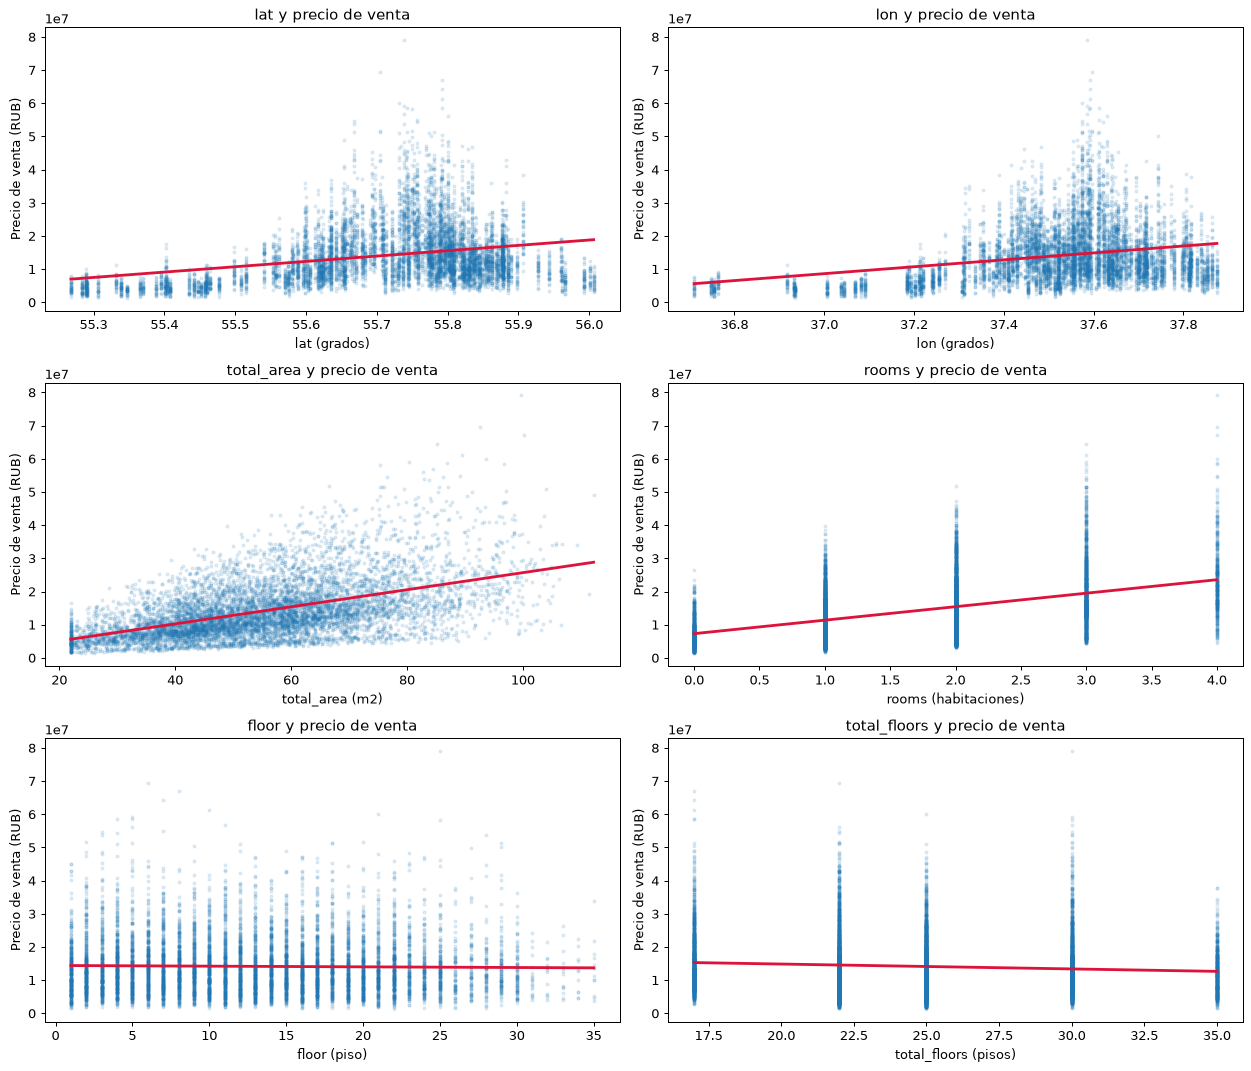

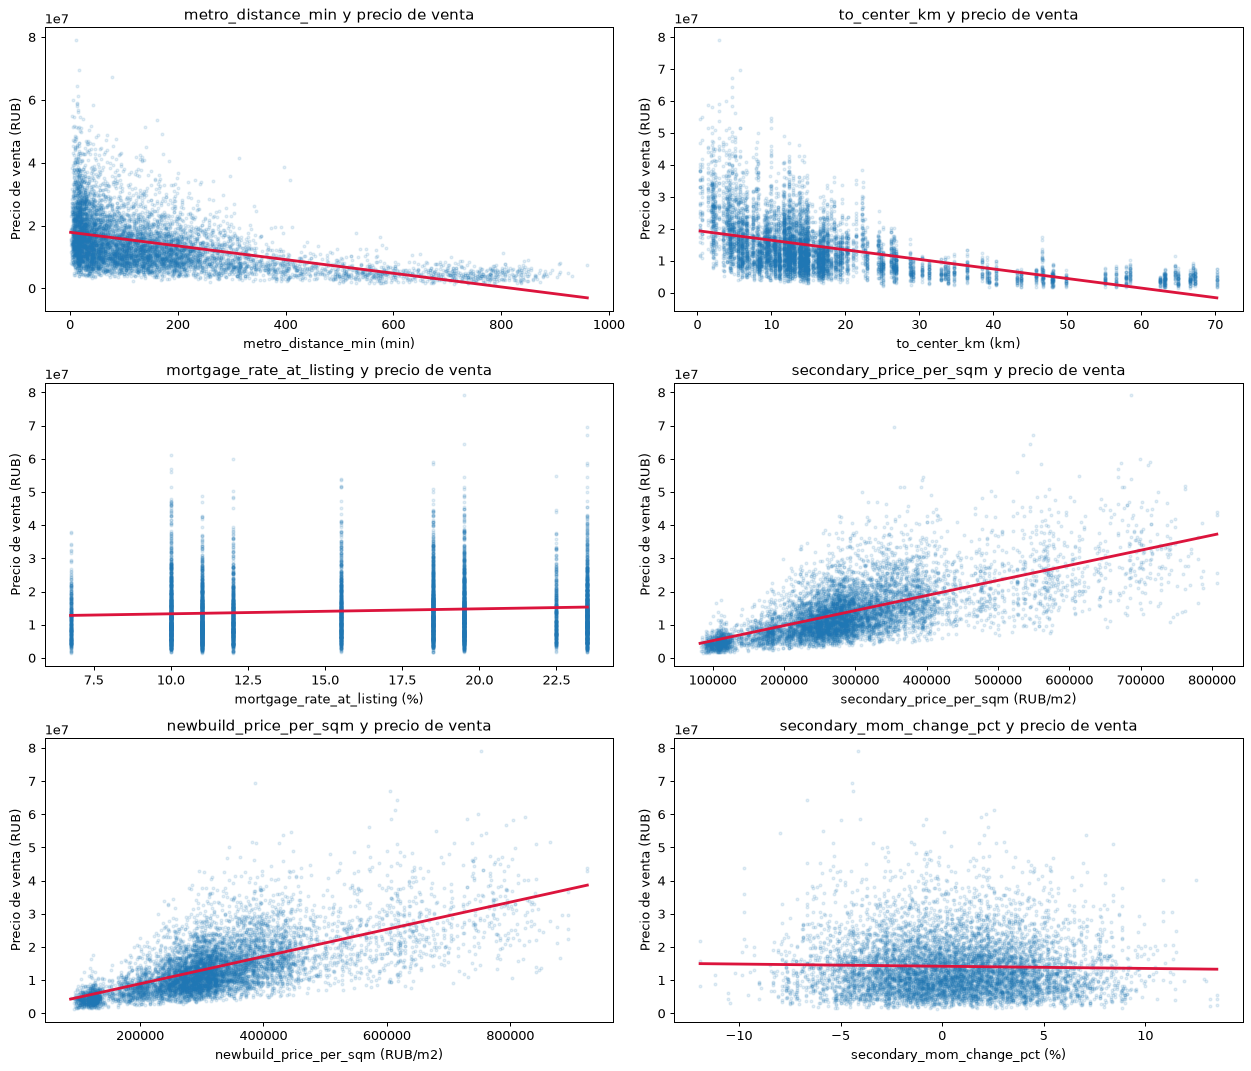

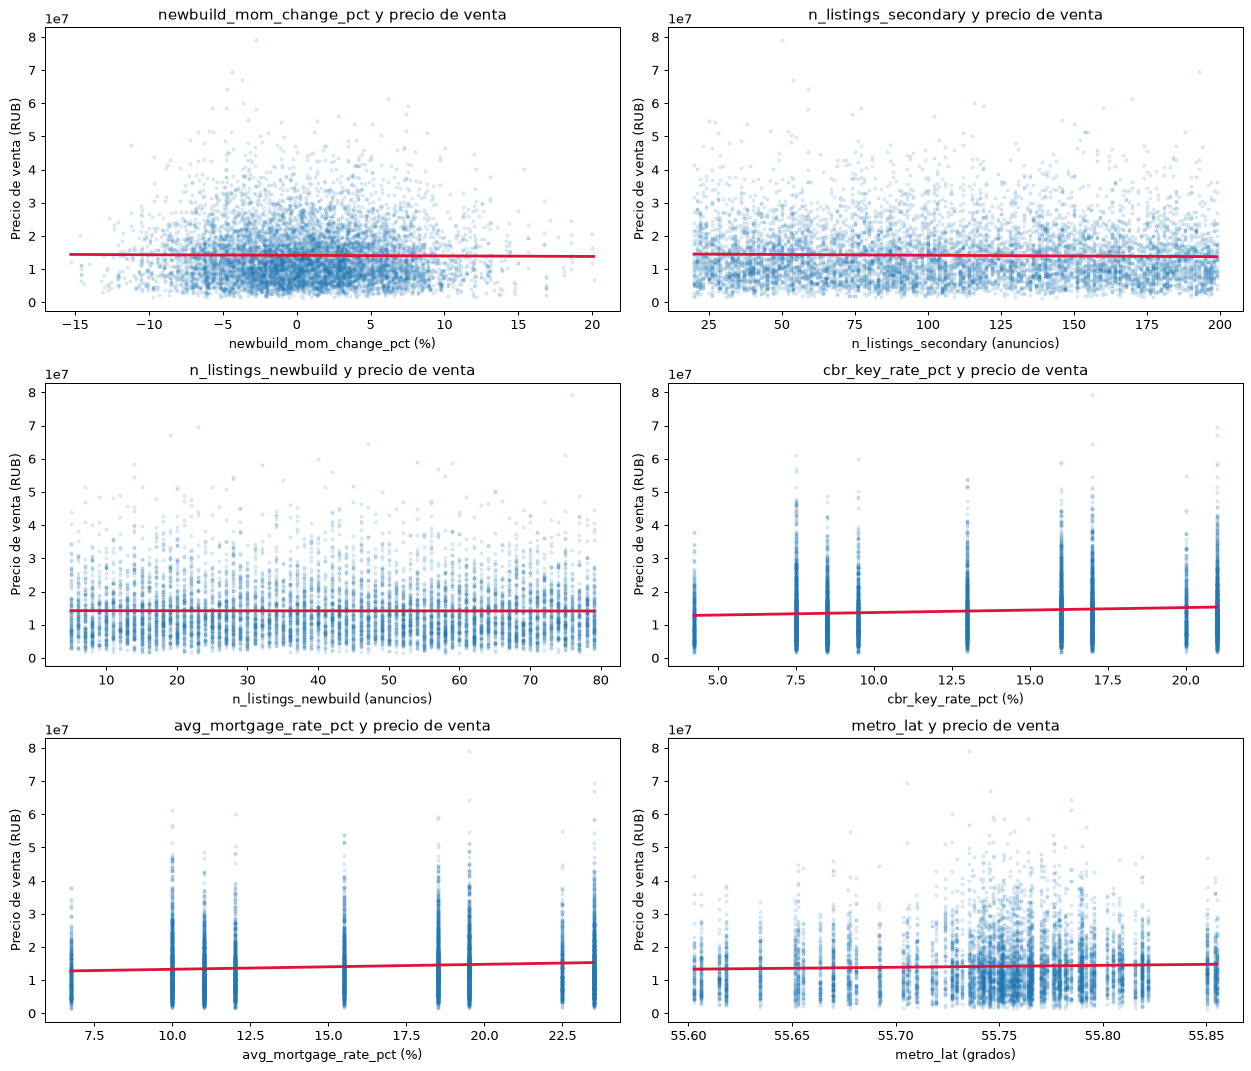

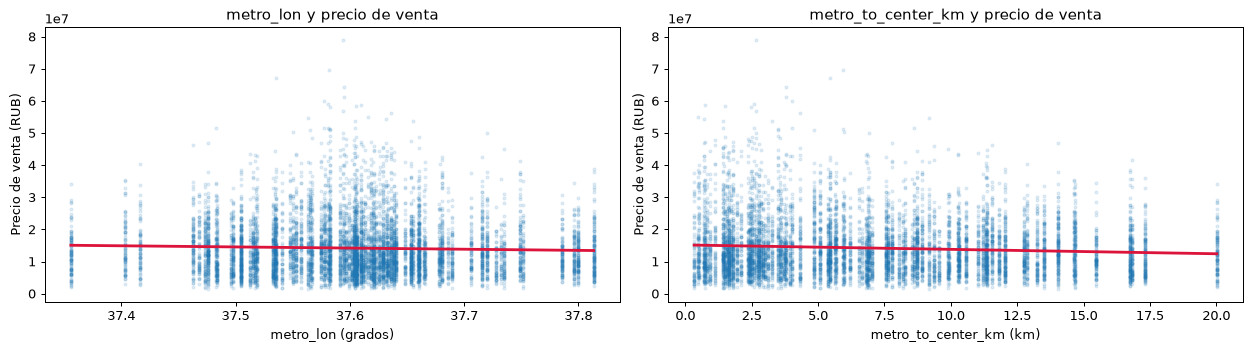

,variable,n,Pearson_r,R2,pendiente_RUB_por_unidad
9,secondary_price_per_sqm,8000,0.669348,0.448026,4.540667e+01
10,newbuild_price_per_sqm,8000,0.668381,0.446733,4.100328e+01
2,total_area,8000,0.520123,0.270528,2.572178e+05
7,to_center_km,8000,-0.508005,0.258070,-2.994027e+05
6,metro_distance_min,8000,-0.476596,0.227143,-2.175281e+04
3,rooms,8000,0.474443,0.225096,4.062766e+06
0,lat,8000,0.286463,0.082061,1.610754e+07
1,lon,8000,0.256805,0.065949,1.041677e+07
8,mortgage_rate_at_listing,8000,0.091134,0.008305,1.501243e+05
15,cbr_key_rate_pct,8000,0.091134,0.008305,1.501243e+05


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress
from IPython.display import display

objetivo = "price_rub"
datos_bivariados = df_venta_enriquecido.copy(deep=True)
exclusiones_bivariadas = {
    "id": "Identificador del anuncio",
    "complex_id": "Identificador del complejo; complex_name conserva su contexto",
    "price_per_sqm": "Derivada directamente del objetivo y de total_area",
    "_merge_district_prices": "Indicador tecnico de correspondencia",
    "_merge_metro_stations": "Indicador tecnico de correspondencia",
    "date_posted": "Representada mediante date_posted_dt",
    "year_month": "Representada mediante la evolucion mensual de date_posted_dt",
}
temporales = [c for c in ["date_posted_dt", "building_year", "completion_year", "metro_year_opened"] if c in datos_bivariados]
binarias = datos_bivariados.select_dtypes(include="bool").columns.tolist()
numericas = [c for c in datos_bivariados.select_dtypes(include="number") if c != objetivo and c not in temporales and c not in exclusiones_bivariadas]
categoricas = [c for c in datos_bivariados.columns if c not in numericas + temporales + binarias + [objetivo] and c not in exclusiones_bivariadas]
display(pd.DataFrame([{"columna": c, "motivo": m} for c, m in exclusiones_bivariadas.items() if c in datos_bivariados]))
display(pd.DataFrame({"tipo": ["Numericas", "Categoricas", "Binarias", "Temporales"], "variables": [", ".join(v) for v in [numericas, categoricas, binarias, temporales]]}))

unidades_bivariadas = {"lat": "grados", "lon": "grados", "metro_lat": "grados", "metro_lon": "grados", "total_area": "m2", "living_area": "m2", "kitchen_area": "m2", "ceiling_height": "m", "metro_distance_min": "min", "to_center_km": "km", "metro_to_center_km": "km", "rooms": "habitaciones", "floor": "piso", "total_floors": "pisos", "mortgage_rate_at_listing": "%", "cbr_key_rate_pct": "%", "avg_mortgage_rate_pct": "%", "secondary_mom_change_pct": "%", "newbuild_mom_change_pct": "%", "secondary_price_per_sqm": "RUB/m2", "newbuild_price_per_sqm": "RUB/m2", "n_listings_secondary": "anuncios", "n_listings_newbuild": "anuncios"}

resultados_regresiones = []
for inicio in range(0, len(numericas), 6):
    lote = numericas[inicio:inicio + 6]
    fig, axes = plt.subplots(int(np.ceil(len(lote) / 2)), 2, figsize=(14, 4 * int(np.ceil(len(lote) / 2))), squeeze=False)
    for ax, variable in zip(axes.flat, lote):
        pares = datos_bivariados[[variable, objetivo]].dropna()
        pares = pares.loc[np.isfinite(pares).all(axis=1)]
        if len(pares) < 3 or pares[variable].nunique() < 2:
            resultados_regresiones.append({"variable": variable, "n": len(pares), "Pearson_r": np.nan, "R2": np.nan, "pendiente_RUB_por_unidad": np.nan})
            ax.text(.5, .5, "Datos insuficientes o variable constante", ha="center", transform=ax.transAxes)
        else:
            ajuste = linregress(pares[variable], pares[objetivo])
            resultados_regresiones.append({"variable": variable, "n": len(pares), "Pearson_r": ajuste.rvalue, "R2": ajuste.rvalue ** 2, "pendiente_RUB_por_unidad": ajuste.slope})
            sns.regplot(data=pares, x=variable, y=objetivo, ci=None, scatter_kws={"s": 5, "alpha": .12, "rasterized": True}, line_kws={"color": "crimson"}, ax=ax)
        ax.set(title=f"{variable} y precio de venta", xlabel=f"{variable} ({unidades_bivariadas.get(variable, 'unidad original')})", ylabel="Precio de venta (RUB)")
    for ax in list(axes.flat)[len(lote):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()
resultados_regresiones = pd.DataFrame(resultados_regresiones)
resultados_regresiones = resultados_regresiones.loc[resultados_regresiones.Pearson_r.abs().sort_values(ascending=False).index]
display(resultados_regresiones)


### Variables categoricas y binarias

Se muestran todas las categorias observadas, ordenadas por mediana, y su cantidad de observaciones. Las diferencias entre grupos no indican efectos causales; categorias con pocos anuncios requieren cautela.

,count,median,mean
complex_name,,,
Polar Residence,270,15722000.0,1.855338e+07
Losiny Ostrov Residence,236,14480000.0,1.544461e+07
Discovery Park Residence,261,14150000.0,1.556838e+07
Level Residence,364,13951500.0,1.562841e+07
Prokshino Residence,421,13763000.0,1.506983e+07
Odintsovo-1 Residence,533,13697000.0,1.518483e+07
ZILART Residence,267,13474000.0,1.688454e+07
Alye Parusa Residence,382,13411000.0,1.557686e+07
Severny Residence,533,13144000.0,1.454585e+07


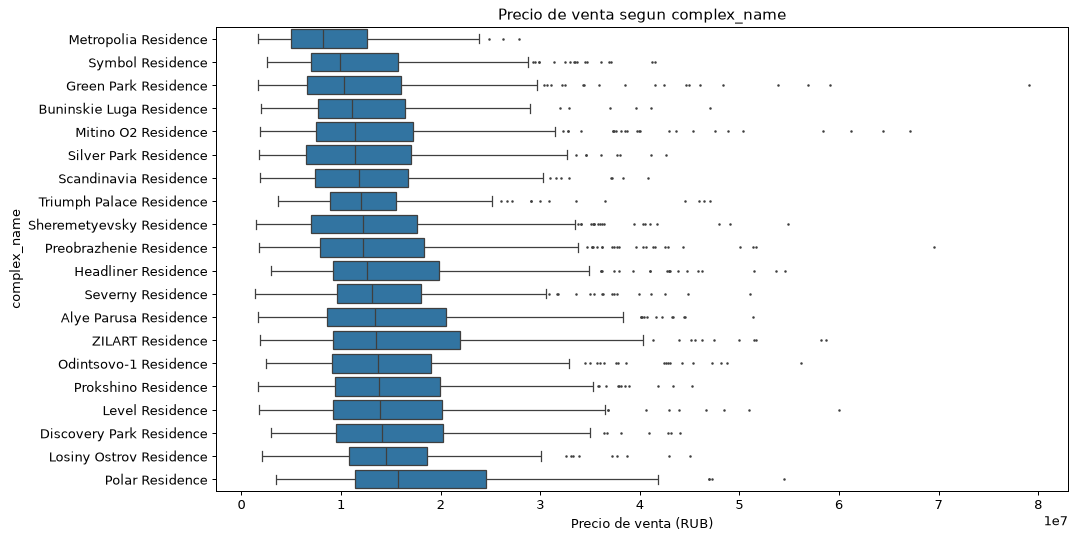

,count,median,mean
developer,,,
DONSTROY,789,14709000.0,1.705109e+07
LSR,855,14484000.0,1.604324e+07
MR Group,814,13841500.0,1.522893e+07
Samolet,529,12632000.0,1.521654e+07
GK A101,716,12402000.0,1.444571e+07
GK Granel,654,12309000.0,1.383144e+07
FSK,795,12209000.0,1.382081e+07
INGRAD,761,11506000.0,1.284094e+07
PIK,820,11144500.0,1.244812e+07


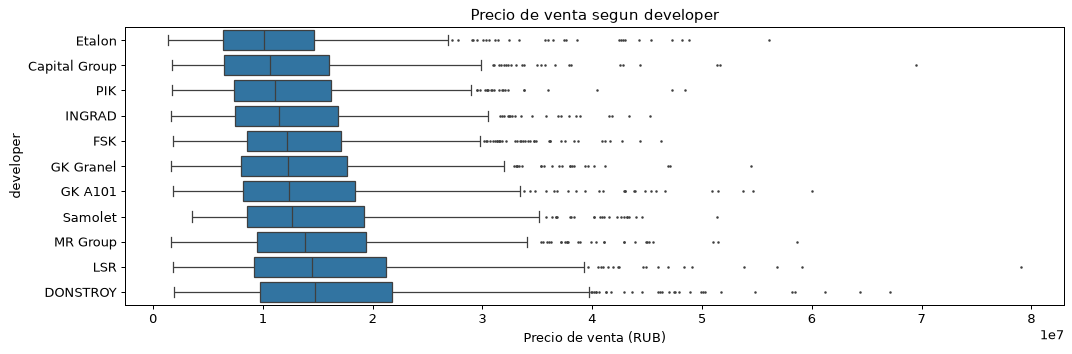

,count,median,mean
complex_class,,,
premium,330,22424000.0,2.340656e+07
business,1748,16707500.0,1.800035e+07
comfort,3314,11753500.0,1.318067e+07
economy,2608,10027000.0,1.172574e+07


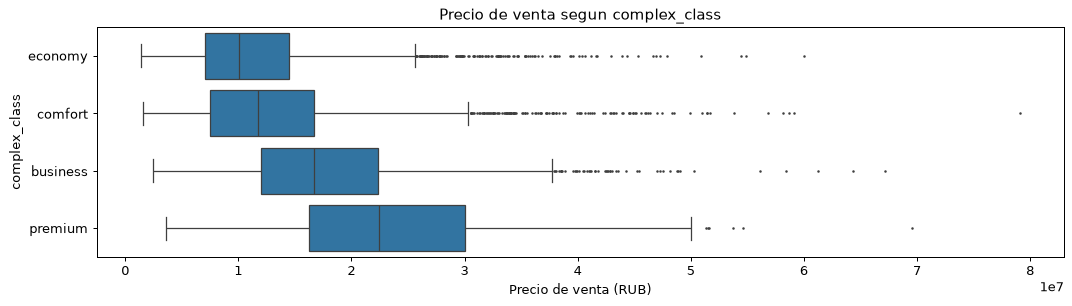

,count,median,mean
district,,,
Arbat,42,29958000.0,3.028083e+07
Yakimanka,89,29877000.0,3.172830e+07
Presnensky,53,28775000.0,2.978791e+07
Khamovniki,34,28554000.0,3.004624e+07
Tverskoy,60,27995000.0,2.878747e+07
...,...,...,...
Kievsky,128,4491500.0,4.694234e+06
Shchapovskoye,57,4432000.0,4.428246e+06
Novofyodorovskoye,100,4383000.0,4.623650e+06


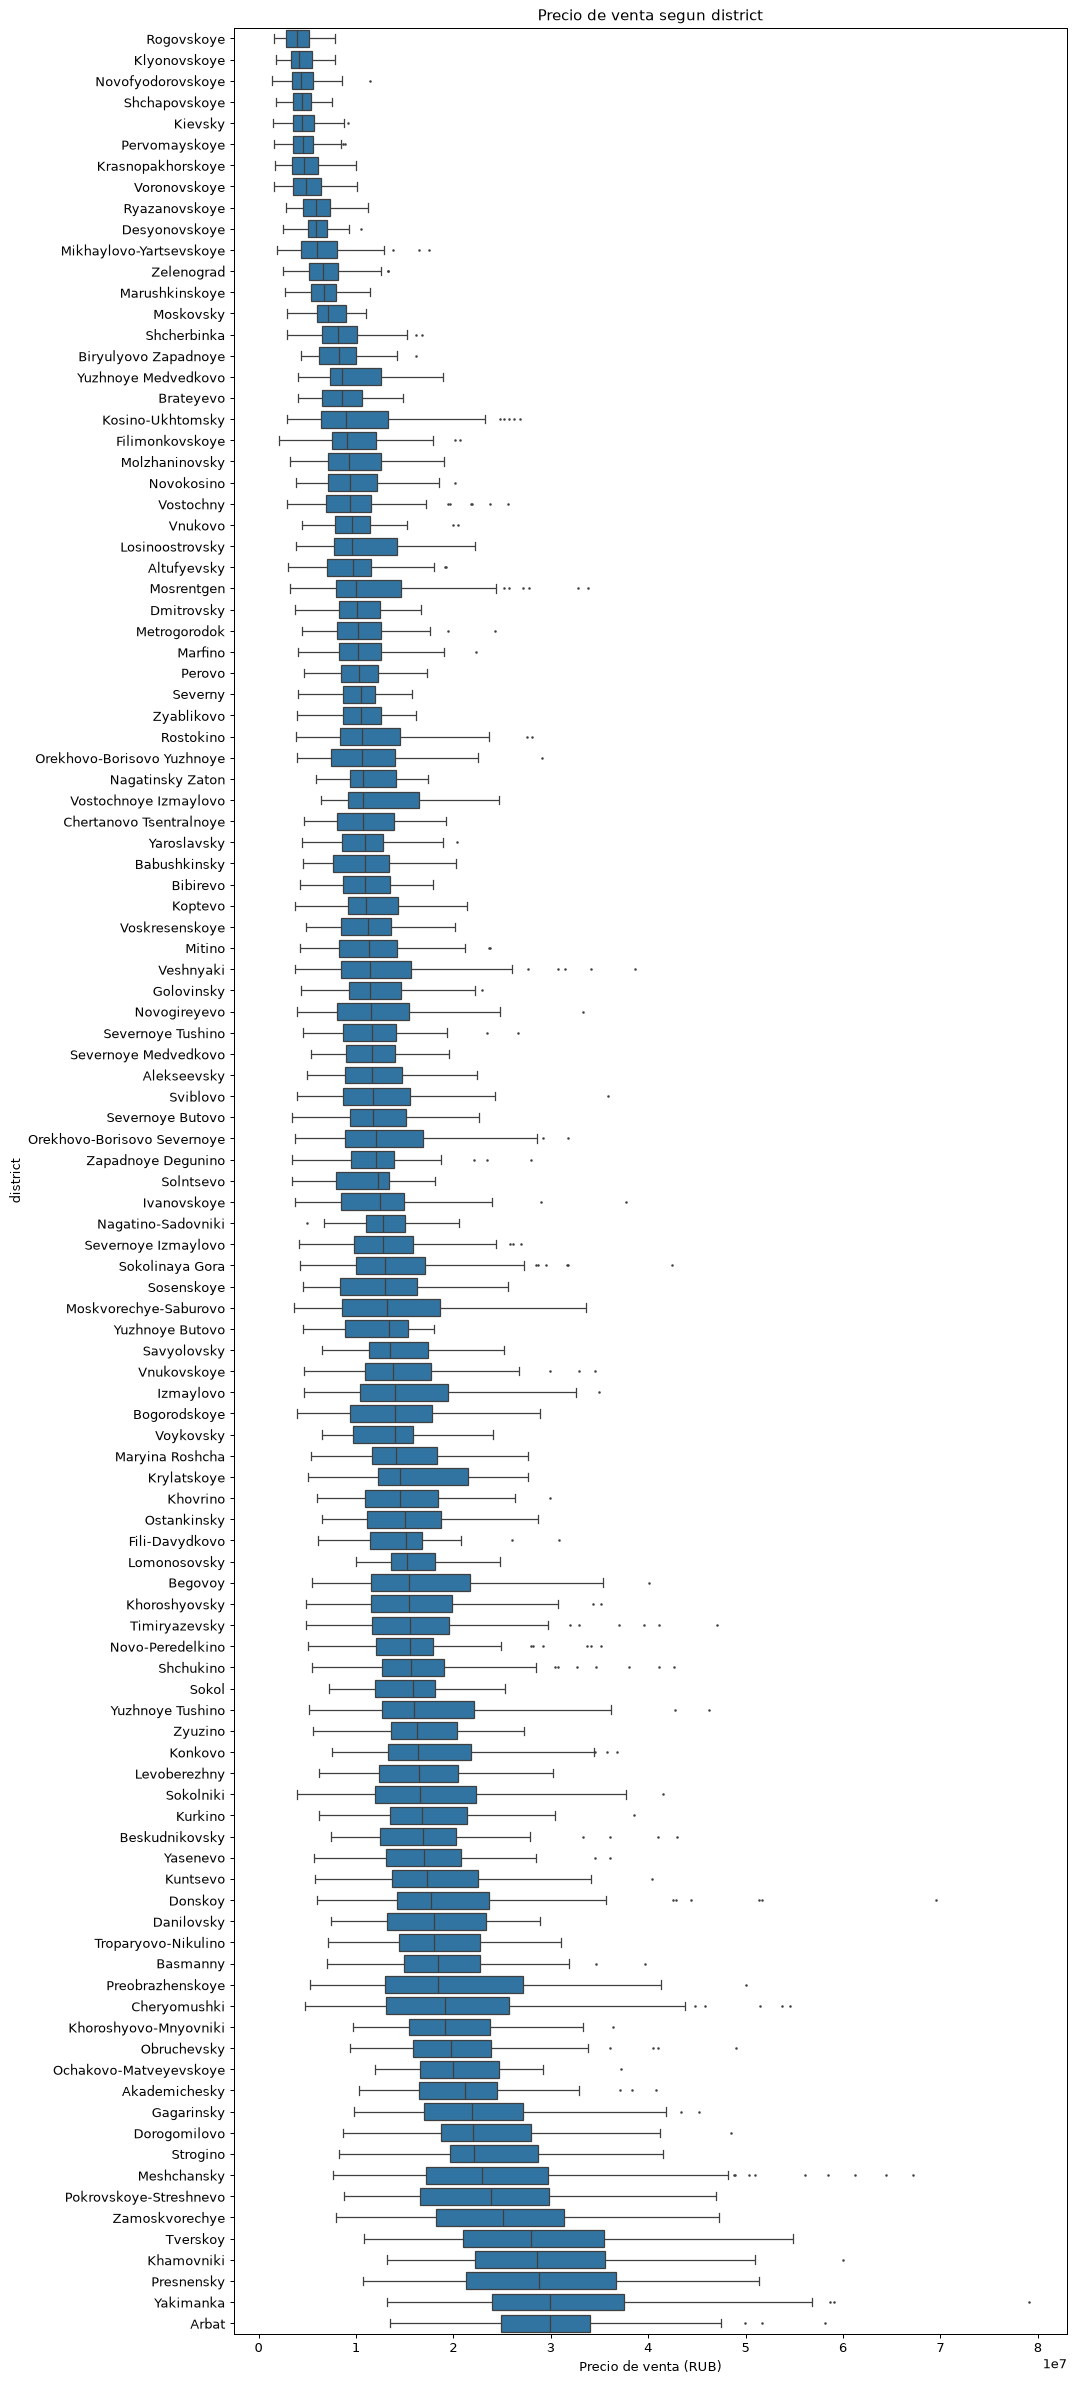

,count,median,mean
okrug,,,
CAO,644,25638000.0,2.691964e+07
YuZAO,780,16438000.0,1.790013e+07
ZAO,486,16243000.0,1.735476e+07
SZAO,661,15386000.0,1.715189e+07
SAO,888,13612000.0,1.450565e+07
YuAO,685,12356000.0,1.378451e+07
VAO,1363,12265000.0,1.359067e+07
SVAO,855,10856000.0,1.146148e+07
NAO,755,8290000.0,9.536038e+06


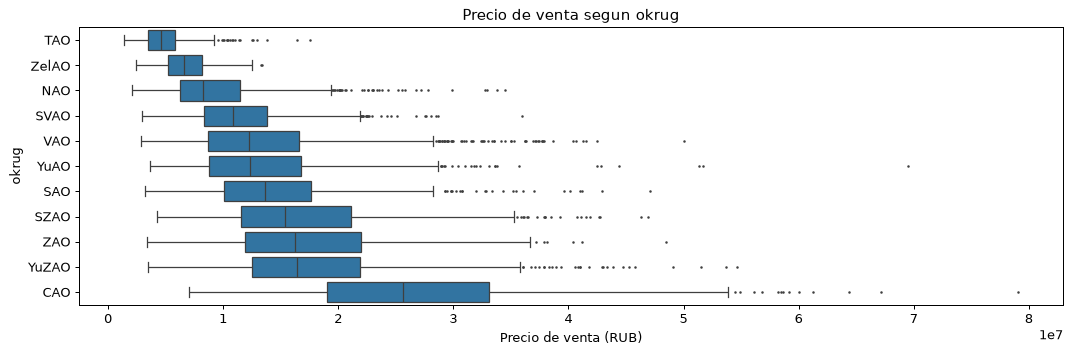

,count,median,mean
ready_status,,,
completed,1012,13575000.0,1.559497e+07
under_construction,6988,12229500.0,1.397655e+07


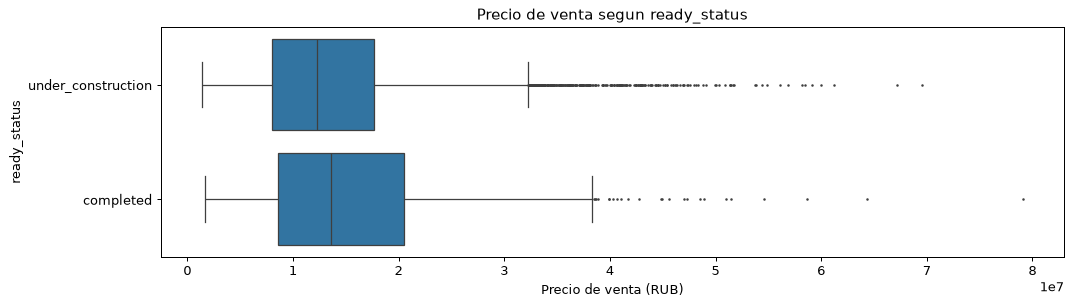

,count,median,mean
metro_station,,,
Sportivnaya,61,19810000.0,1.962266e+07
Park Kultury,60,15886000.0,1.955282e+07
Begovaya,64,15453000.0,1.736125e+07
Dinamo,88,15306000.0,1.629920e+07
Shchukinskaya,99,15282000.0,1.564854e+07
...,...,...,...
Ploshchad Revolyutsii,66,9672000.0,1.237306e+07
Taganskaya,57,9655000.0,1.186242e+07
Pionerskaya,59,9619000.0,1.157139e+07


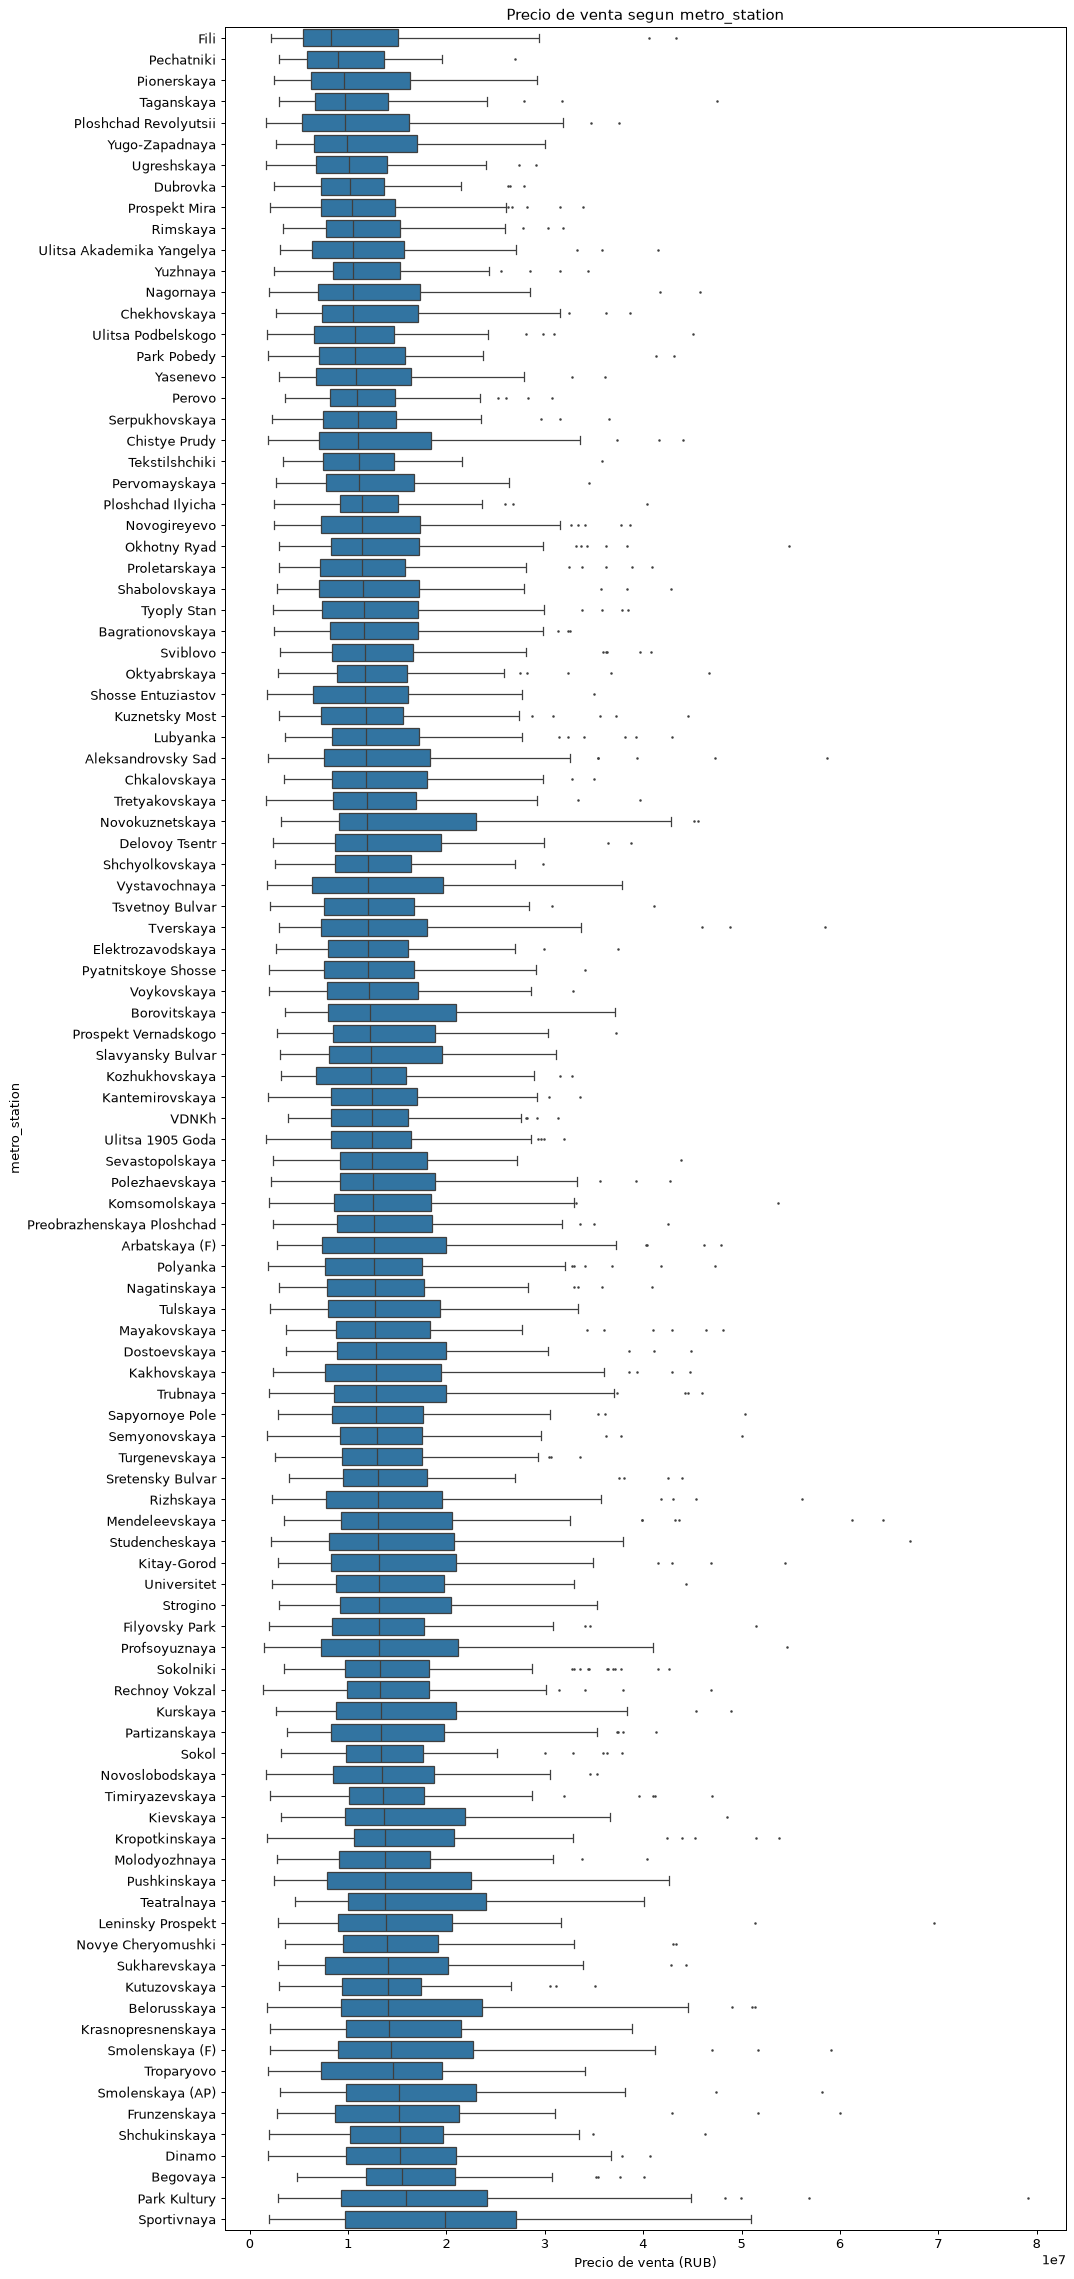

,count,median,mean
metro_line,,,
Zamoskvoretskaya,848,13053000.0,1.481861e+07
Tagansko-Krasnopresnenskaya,529,13026000.0,1.458951e+07
Koltsevaya,685,12839000.0,1.532256e+07
Bolshaya Koltsevaya,193,12822000.0,1.467195e+07
Sokolnicheskaya,1053,12651000.0,1.469451e+07
Kaluzhsko-Rizhskaya,1099,12478000.0,1.397124e+07
Arbatsko-Pokrovskaya,996,12403500.0,1.380913e+07
Filyovskaya,627,12223000.0,1.428429e+07
Serpukhovsko-Timiryazevskaya,955,11951000.0,1.363789e+07


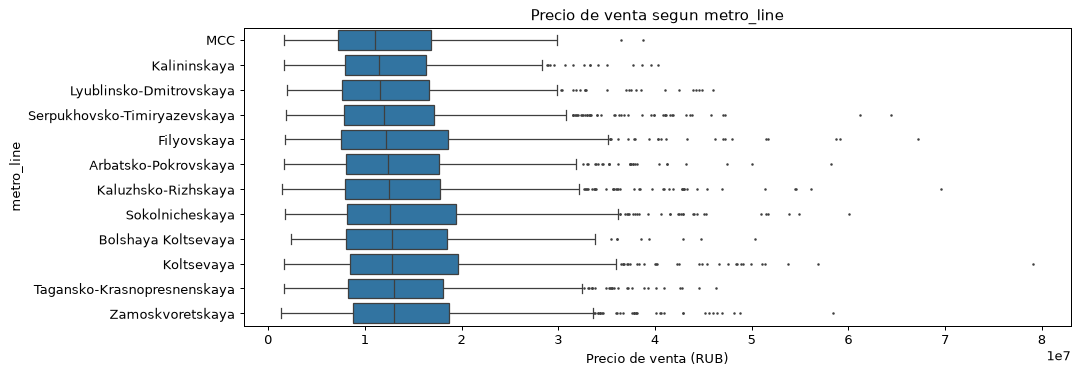

,count,median,mean
deal_type,,,
trade-in,1208,12620500.0,1.422849e+07
DDU,4391,12462000.0,1.418645e+07
FZ214,1624,12350500.0,1.422981e+07
installment,777,11954000.0,1.397722e+07


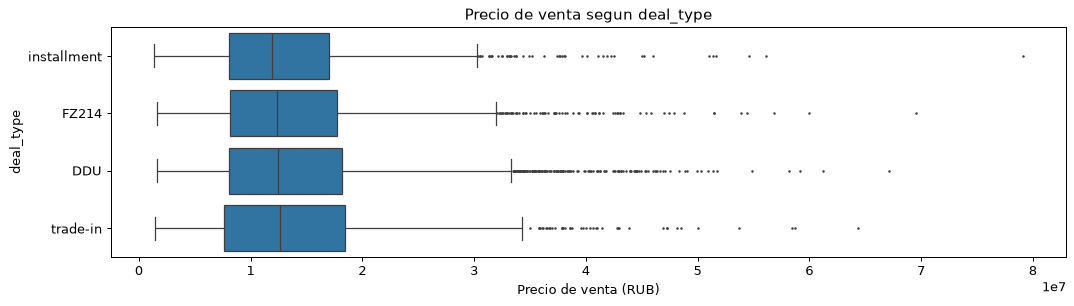

,count,median,mean
subsidized_mortgage,,,
False,2753,13107000.0,1.490431e+07
True,5247,12019000.0,1.380192e+07


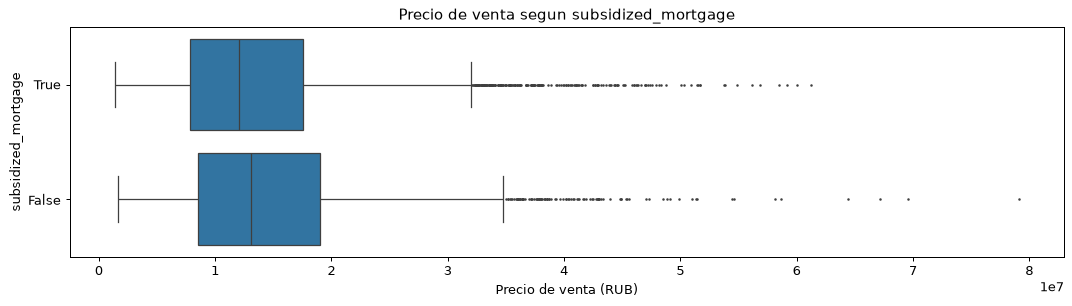

complex_name
developer
complex_class
district
okrug
ready_status
metro_station
metro_line
deal_type
subsidized_mortgage


In [ ]:
resumen_grupos = {}
for variable in categoricas + binarias:
    grupos = datos_bivariados.groupby(variable, observed=True)[objetivo].agg(["count", "median", "mean"])
    resumen_grupos[variable] = grupos
    print(variable)
    display(grupos.sort_values("median", ascending=False))
    orden = grupos.sort_values("median").index.tolist()
    fig, ax = plt.subplots(figsize=(12, max(3.5, .23 * len(orden) + 1.5)))
    sns.boxplot(data=datos_bivariados, y=variable, x=objetivo, order=orden, orient="h", ax=ax, fliersize=1)
    ax.set(title=f"Precio de venta segun {variable}", xlabel="Precio de venta (RUB)", ylabel=variable)
    fig.tight_layout()
    plt.show()


### Variables temporales

Las fechas de publicacion se resumen por mes. Los anios de construccion, entrega o inauguracion se interpretan como cohortes: estos graficos comparan precios por cohorte, no el seguimiento de una misma propiedad en el tiempo.

,count,median,mean
date_posted_dt,,,
2021-01,121,10628000.0,1.171234e+07
2021-02,121,10194000.0,1.156623e+07
2021-03,119,9816000.0,1.172910e+07
2021-04,123,10086000.0,1.170825e+07
2021-05,136,9787500.0,1.145075e+07
...,...,...,...
2025-12,115,12954000.0,1.588253e+07
2026-01,107,14113000.0,1.527841e+07
2026-02,102,12364000.0,1.430911e+07


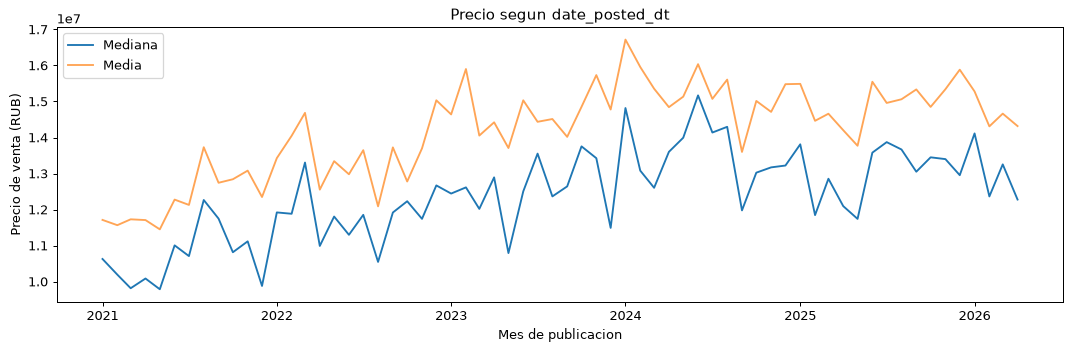

,count,median,mean
completion_year,,,
2024,755,13255000.0,1.503828e+07
2025,2167,12495000.0,1.456448e+07
2026,2491,12475000.0,1.419066e+07
2027,2000,11566000.0,1.296677e+07
2028,587,13672000.0,1.576262e+07


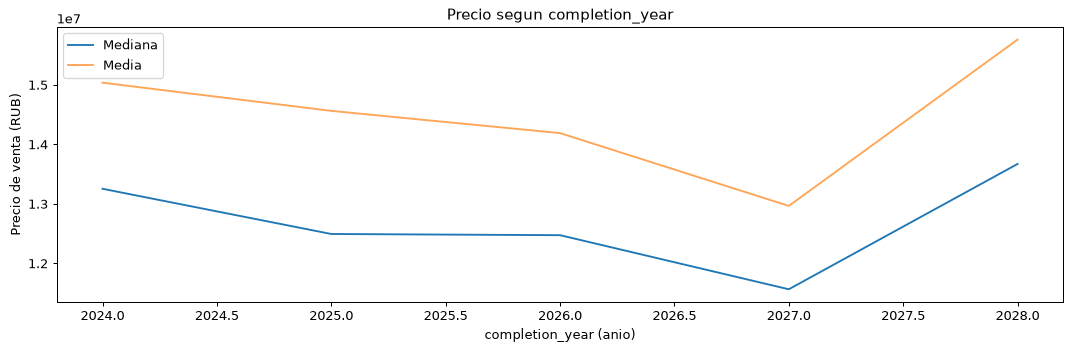

,count,median,mean
metro_year_opened,,,
1935,589,12261000.0,1.529432e+07
1938,383,13456000.0,1.506102e+07
1943,66,11955500.0,1.715105e+07
1944,265,12891000.0,1.432512e+07
1950,252,12306000.0,1.554510e+07
1952,304,12567500.0,1.478171e+07
1953,68,15187500.0,1.694619e+07
1954,129,14137000.0,1.616238e+07
1957,129,16361000.0,1.805015e+07


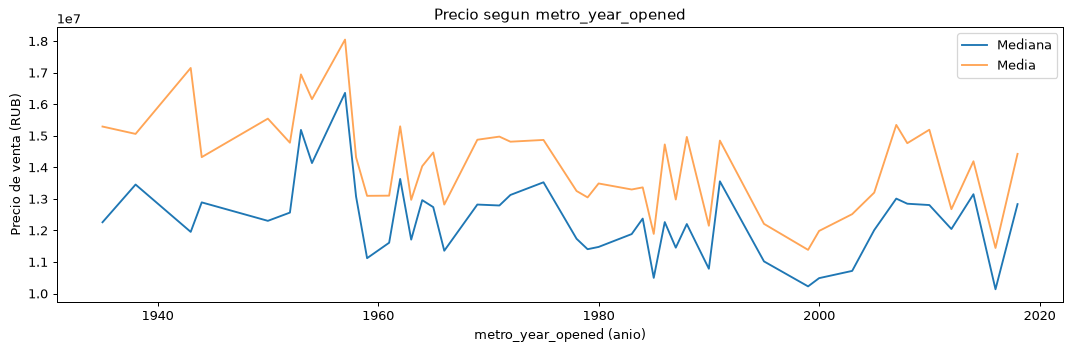

In [ ]:
evoluciones_temporales = {}
for variable in temporales:
    clave = datos_bivariados[variable].dt.to_period("M") if variable == "date_posted_dt" else datos_bivariados[variable]
    evolucion = datos_bivariados.groupby(clave, observed=True)[objetivo].agg(["count", "median", "mean"]).sort_index()
    evoluciones_temporales[variable] = evolucion
    display(evolucion)
    fig, ax = plt.subplots(figsize=(12, 4))
    x = evolucion.index.to_timestamp() if variable == "date_posted_dt" else evolucion.index
    ax.plot(x, evolucion["median"], label="Mediana")
    ax.plot(x, evolucion["mean"], label="Media", alpha=.7)
    ax.set(title=f"Precio segun {variable}", xlabel="Mes de publicacion" if variable == "date_posted_dt" else f"{variable} (anio)", ylabel="Precio de venta (RUB)")
    ax.legend()
    fig.tight_layout()
    plt.show()


<a id="correlacion"></a>

## 6. Matriz de correlacion y multicolinealidad

[Volver al indice](#indice)

Pearson se calcula sobre pares disponibles; se muestra tambien su cantidad de observaciones. Se incluyen variables binarias (0/1) y anios numericos. Se excluyen IDs y la variable derivada del objetivo. El umbral exploratorio es |r| >= 0,80 entre predictores. Una correlacion elevada puede reflejar informacion redundante y dificultar interpretar coeficientes en futuros modelos multiples; no demuestra por si sola multicolinealidad completa. VIF y seleccion se evaluaran despues. Los indicadores mensuales compartidos por distrito/mes repiten contexto entre anuncios: las filas no son observaciones independientes de ese contexto.

,lat,lon,total_area,rooms,floor,total_floors,completion_year,metro_distance_min,to_center_km,price_rub,subsidized_mortgage,mortgage_rate_at_listing,secondary_price_per_sqm,newbuild_price_per_sqm,secondary_mom_change_pct,newbuild_mom_change_pct,n_listings_secondary,n_listings_newbuild,cbr_key_rate_pct,avg_mortgage_rate_pct,metro_lat,metro_lon,metro_year_opened,metro_to_center_km
lat,1.000000,0.499311,0.011853,0.014447,-0.033100,-0.070666,0.073624,-0.640095,-0.701002,0.286463,-0.018597,0.020883,0.405182,0.403408,0.002221,-0.002152,-0.015854,0.003551,0.020883,0.020883,0.385081,0.037768,-0.076127,-0.081438
lon,0.499311,1.000000,-0.001130,0.003550,0.027983,0.059145,0.001654,-0.739025,-0.789366,0.256805,-0.005589,0.013909,0.355853,0.354592,-0.015547,-0.002897,0.001605,-0.010036,0.013909,0.013909,0.071212,0.338026,-0.068699,-0.045678
total_area,0.011853,-0.001130,1.000000,0.917077,0.014464,0.006194,-0.023219,-0.010733,-0.007867,0.520123,0.014805,-0.002305,0.001797,0.001933,-0.018171,-0.006281,0.022361,0.009932,-0.002305,-0.002305,-0.008453,-0.000512,0.016238,0.006779
rooms,0.014447,0.003550,0.917077,1.000000,0.012995,-0.002440,-0.023226,-0.012120,-0.008205,0.474443,0.009239,-0.004219,-0.002699,-0.002783,-0.015491,-0.007888,0.023131,-0.004739,-0.004219,-0.004219,-0.010018,-0.002875,0.015789,0.001845
floor,-0.033100,0.027983,0.014464,0.012995,1.000000,0.320615,-0.018254,0.014098,0.010279,-0.018513,-0.004928,0.019242,-0.028441,-0.028286,0.000344,0.003783,-0.003182,-0.001315,0.019242,0.019242,-0.023384,0.023397,-0.004554,-0.006383
total_floors,-0.070666,0.059145,0.006194,-0.002440,0.320615,1.000000,-0.078360,0.018190,0.024204,-0.085796,-0.007767,0.001456,-0.093385,-0.092551,-0.003319,0.005443,0.012584,-0.034570,0.001456,0.001456,-0.057778,0.060695,0.015341,0.014075
completion_year,0.073624,0.001654,-0.023219,-0.023226,-0.018254,-0.078360,1.000000,-0.048287,-0.057497,-0.036193,0.004805,0.008252,-0.017167,-0.016073,-0.015020,-0.015396,0.017968,-0.015618,0.008252,0.008252,0.062874,-0.027347,-0.008329,-0.033220
metro_distance_min,-0.640095,-0.739025,-0.010733,-0.012120,0.014098,0.018190,-0.048287,1.000000,0.928063,-0.476596,0.003348,-0.009855,-0.617786,-0.616089,0.007797,0.003283,0.015529,-0.004041,-0.009855,-0.009855,-0.032442,-0.013235,0.011368,-0.124474
to_center_km,-0.701002,-0.789366,-0.007867,-0.008205,0.010279,0.024204,-0.057497,0.928063,1.000000,-0.508005,0.001184,-0.010902,-0.701803,-0.699784,0.008770,-0.000805,0.014575,0.010103,-0.010902,-0.010902,-0.119774,-0.091774,0.085129,0.100304
price_rub,0.286463,0.256805,0.520123,0.474443,-0.018513,-0.085796,-0.036193,-0.476596,-0.508005,1.000000,-0.061282,0.091134,0.669348,0.668381,-0.028227,-0.010462,-0.026402,-0.003323,0.091134,0.091134,0.039887,-0.037573,-0.073076,-0.078424


,lat,lon,total_area,rooms,floor,total_floors,completion_year,metro_distance_min,to_center_km,price_rub,subsidized_mortgage,mortgage_rate_at_listing,secondary_price_per_sqm,newbuild_price_per_sqm,secondary_mom_change_pct,newbuild_mom_change_pct,n_listings_secondary,n_listings_newbuild,cbr_key_rate_pct,avg_mortgage_rate_pct,metro_lat,metro_lon,metro_year_opened,metro_to_center_km
lat,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000
lon,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000
total_area,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000
rooms,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000
floor,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000
total_floors,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000
completion_year,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000
metro_distance_min,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000
to_center_km,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000
price_rub,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000,8000


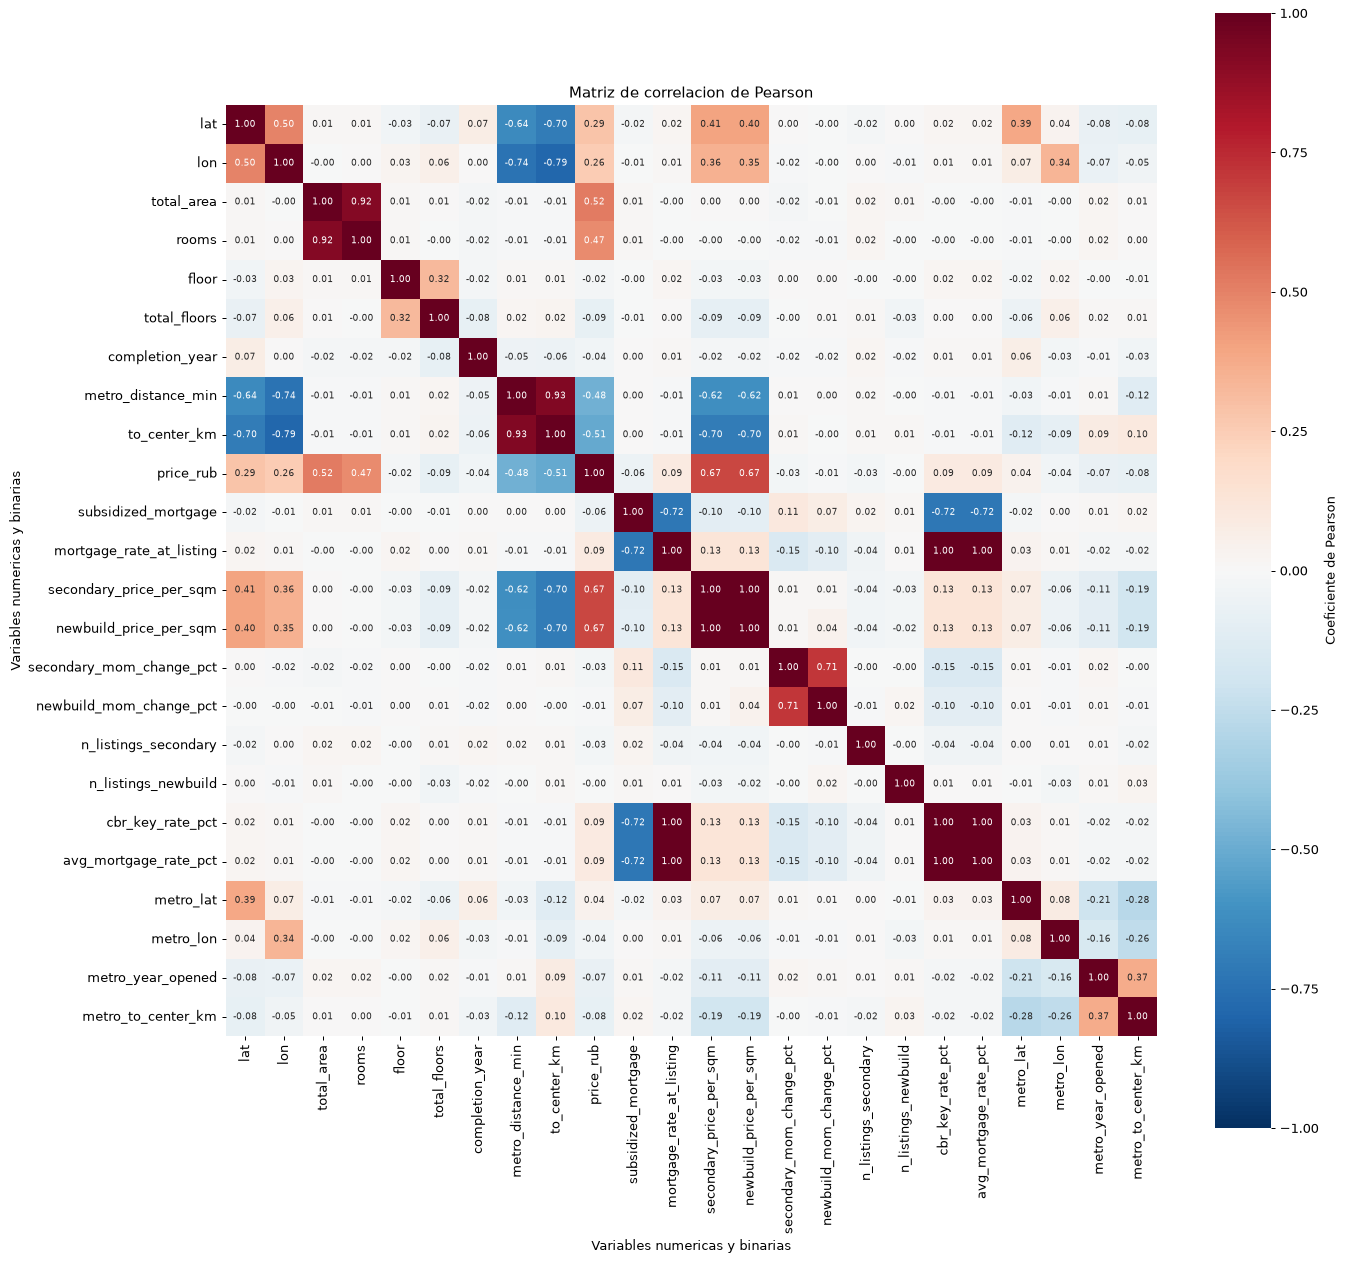

,variable_1,variable_2,Pearson_r,n_pares,ambas_del_join
3,mortgage_rate_at_listing,avg_mortgage_rate_pct,1.000000,8000,False
2,mortgage_rate_at_listing,cbr_key_rate_pct,1.000000,8000,False
5,cbr_key_rate_pct,avg_mortgage_rate_pct,1.000000,8000,True
4,secondary_price_per_sqm,newbuild_price_per_sqm,0.997954,8000,True
1,metro_distance_min,to_center_km,0.928063,8000,False
0,total_area,rooms,0.917077,8000,False


,variable_1,variable_2,Pearson_r,n_pares,ambas_del_join
5,cbr_key_rate_pct,avg_mortgage_rate_pct,1.000000,8000,True
4,secondary_price_per_sqm,newbuild_price_per_sqm,0.997954,8000,True


In [ ]:
variables_correlacion = [c for c in datos_bivariados.select_dtypes(include=["number", "bool"]) if c not in exclusiones_bivariadas]
matriz_correlacion = datos_bivariados[variables_correlacion].corr(method="pearson")
conteos_pares = datos_bivariados[variables_correlacion].notna().astype(int).T.dot(datos_bivariados[variables_correlacion].notna().astype(int))
display(matriz_correlacion)
display(conteos_pares)
fig, ax = plt.subplots(figsize=(max(14, len(variables_correlacion) * .65), max(12, len(variables_correlacion) * .6)))
sns.heatmap(matriz_correlacion, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "Coeficiente de Pearson"})
ax.set(title="Matriz de correlacion de Pearson", xlabel="Variables numericas y binarias", ylabel="Variables numericas y binarias")
fig.tight_layout()
plt.show()
columnas_join = set(district_sales_columns + metro_added_columns)
pares_altos = []
for i, a in enumerate(variables_correlacion):
    for b in variables_correlacion[i + 1:]:
        r = matriz_correlacion.loc[a, b]
        if objetivo not in (a, b) and pd.notna(r) and abs(r) >= .80:
            pares_altos.append({"variable_1": a, "variable_2": b, "Pearson_r": r, "n_pares": conteos_pares.loc[a, b], "ambas_del_join": a in columnas_join and b in columnas_join})
pares_correlacion_alta = pd.DataFrame(pares_altos, columns=["variable_1", "variable_2", "Pearson_r", "n_pares", "ambas_del_join"])
if not pares_correlacion_alta.empty:
    pares_correlacion_alta = pares_correlacion_alta.loc[pares_correlacion_alta.Pearson_r.abs().sort_values(ascending=False).index]
display(pares_correlacion_alta)
display(pares_correlacion_alta.loc[pares_correlacion_alta.ambas_del_join])


<a id="resumen-bivariado"></a>

## 7. Resumen del analisis bivariado

[Volver al indice](#indice)

Asociaciones positivas mas altas: `secondary_price_per_sqm` (r=0.669), `newbuild_price_per_sqm` (r=0.668), `total_area` (r=0.520), `rooms` (r=0.474).

Asociaciones negativas mas altas: `to_center_km` (r=-0.508), `metro_distance_min` (r=-0.477), `total_floors` (r=-0.086), `metro_to_center_km` (r=-0.078).

Relaciones lineales debiles (|r| < 0,20): `floor` (r=-0.019), `total_floors` (r=-0.086), `completion_year` (r=-0.036), `subsidized_mortgage` (r=-0.061), `mortgage_rate_at_listing` (r=0.091), `secondary_mom_change_pct` (r=-0.028), `newbuild_mom_change_pct` (r=-0.010), `n_listings_secondary` (r=-0.026), `n_listings_newbuild` (r=-0.003), `cbr_key_rate_pct` (r=0.091), `avg_mortgage_rate_pct` (r=0.091), `metro_lat` (r=0.040), `metro_lon` (r=-0.038), `metro_year_opened` (r=-0.073), `metro_to_center_km` (r=-0.078). Un Pearson bajo no descarta una relacion no lineal; los diagramas permiten examinar dispersion, agrupamientos y curvatura sin concluir no linealidad solo a partir de r.

Pares de predictores con |r| >= 0,80: mortgage_rate_at_listing / avg_mortgage_rate_pct (r=1.000); mortgage_rate_at_listing / cbr_key_rate_pct (r=1.000); cbr_key_rate_pct / avg_mortgage_rate_pct (r=1.000); secondary_price_per_sqm / newbuild_price_per_sqm (r=0.998); metro_distance_min / to_center_km (r=0.928); total_area / rooms (r=0.917)

La tabla anterior identifica especificamente los pares incorporados por los joins. Se conservan todas las variables para evaluar redundancia y VIF en una etapa posterior. Las asociaciones son descriptivas y no causales.

### Comparacion entre mercados

Nuevas: secondary_price_per_sqm (r=0.669), newbuild_price_per_sqm (r=0.668), total_area (r=0.520). Usadas: secondary_price_per_sqm (|r|=0.791), newbuild_price_per_sqm (|r|=0.789), to_center_km (|r|=0.533).

El mercado nuevo aporta clase, desarrollador, estado y anio de entrega e hipoteca subsidiada; el usado incorpora tipologia y anio de construccion, renovacion, balcon y superficies habitable y de cocina. Estas comparaciones corresponden a muestras distintas (8.000 y 50.000 anuncios) y no aislan efectos del tipo de mercado.


## Exportación del dataset integrado

Se utiliza directamente **`df_venta_enriquecido`**, resultado de los LEFT JOIN ya implementados con precios mensuales por distrito y con estaciones de metro. No se vuelven a definir las uniones en esta sección. Se conservan las 25 variables originales y las 16 columnas incorporadas o generadas en la integración, incluidos identificadores, precios, fechas e indicadores técnicos de correspondencia.

Antes de exportar se comprueban las 8.000 observaciones, la unicidad de `id`, los valores faltantes, las claves y la conservación de los datos originales. La repetición de `complex_id` es esperable: distintas unidades pueden pertenecer al mismo complejo. No se crean transformaciones OLS ni se imputan o eliminan datos.

El archivo se guarda sin índice en `Ventas/Propiedades_Nuevas/data/newbuilds_integrado.csv`. Para regenerarlo, ejecutar las celdas de carga e integración existentes y esta sección, o ejecutar el notebook completo. Los CSV originales permanecen intactos.

In [22]:
# Recuperar el resultado existente, sin rehacer ni modificar las uniones.
from pathlib import Path
import pandas as pd
from IPython.display import display

df_exportacion = df_venta_enriquecido
claves_distrito_exportacion = ["year_month", "district", "okrug"]
claves_metro_exportacion = ["metro_station", "metro_line"]
columnas_originales_exportacion = df.columns.tolist()
columnas_esperadas_exportacion = (
    columnas_originales_exportacion + ["date_posted_dt", "year_month"]
    + district_sales_columns + ["_merge_district_prices"]
    + metro_added_columns + ["_merge_metro_stations"]
)

control_exportacion = pd.Series({
    "observaciones_originales": len(df),
    "observaciones_integradas": len(df_exportacion),
    "columnas_originales": df.shape[1],
    "columnas_integradas": df_exportacion.shape[1],
    "id_unicos": df_exportacion["id"].nunique(),
    "id_nulos": df_exportacion["id"].isna().sum(),
    "id_duplicados": df_exportacion["id"].duplicated().sum(),
    "filas_duplicadas": df_exportacion.duplicated().sum(),
    "complejos_unicos": df_exportacion["complex_id"].nunique(),
    "celdas_nulas": df_exportacion.isna().sum().sum(),
}, name="valor")
display(control_exportacion.to_frame())

auditoria_claves_exportacion = pd.DataFrame([
    {"dataset": nombre, "claves": ", ".join(claves),
     "filas_con_clave_nula": int(tabla[claves].isna().any(axis=1).sum()),
     "claves_repetidas": int(tabla.duplicated(claves).sum())}
    for nombre, tabla, claves in [
        ("Auxiliar precios", district_prices_sales, claves_distrito_exportacion),
        ("Auxiliar metro", metro_stations_sales, claves_metro_exportacion),
        ("Integrado: distrito/mes", df_exportacion, claves_distrito_exportacion),
        ("Integrado: estación/línea", df_exportacion, claves_metro_exportacion),
    ]
])
display(auditoria_claves_exportacion)
print("Las claves repetidas de distrito/mes o estación/línea en anuncios son esperables; los auxiliares deben ser únicos.")

correspondencias_exportacion = pd.DataFrame([
    {"join": nombre, "con_match": int(df_exportacion[indicador].eq("both").sum()),
     "sin_match": int(df_exportacion[indicador].ne("both").sum()),
     "coincidencia_pct": df_exportacion[indicador].eq("both").mean() * 100}
    for nombre, indicador in [("Precios distritales", "_merge_district_prices"), ("Estaciones de metro", "_merge_metro_stations")]
])
display(correspondencias_exportacion)

faltantes_exportacion = pd.DataFrame({"nulos": df_exportacion.isna().sum(),
                                      "porcentaje_nulos": df_exportacion.isna().mean() * 100})
display(faltantes_exportacion.rename_axis("variable").reset_index())

assert len(df) == len(df_venta_district_prices) == len(df_exportacion) == 8000
assert df_exportacion.columns.is_unique
assert df_exportacion.columns.tolist() == columnas_esperadas_exportacion
assert df_exportacion.shape[1] == 41
assert df_exportacion["id"].notna().all() and df_exportacion["id"].is_unique
assert not df_exportacion.duplicated().any()
assert auditoria_claves_exportacion["filas_con_clave_nula"].eq(0).all()
assert auditoria_claves_exportacion.loc[:1, "claves_repetidas"].eq(0).all()
assert correspondencias_exportacion["sin_match"].eq(0).all()
pd.testing.assert_frame_equal(
    df_exportacion[columnas_originales_exportacion].reset_index(drop=True),
    df.reset_index(drop=True), check_exact=True,
)
fechas_originales_exportacion = pd.to_datetime(df_exportacion["date_posted"], format="%Y-%m-%d", errors="raise")
pd.testing.assert_series_equal(fechas_originales_exportacion, df_exportacion["date_posted_dt"], check_names=False)
assert df_exportacion["year_month"].eq(df_exportacion["date_posted_dt"].dt.strftime("%Y-%m")).all()

# Comprobar los valores añadidos contra los auxiliares por sus claves únicas.
# reindex solo alinea la referencia de auditoría; no vuelve a integrar el dataset.
for auxiliar, claves, columnas in [
    (district_prices_sales, claves_distrito_exportacion, district_sales_columns),
    (metro_stations_sales, claves_metro_exportacion, metro_added_columns),
]:
    referencia = auxiliar.set_index(claves).reindex(pd.MultiIndex.from_frame(df_exportacion[claves]))
    pd.testing.assert_frame_equal(
        df_exportacion[columnas].reset_index(drop=True),
        referencia[columnas].reset_index(drop=True), check_exact=True,
    )
print("Validación previa aprobada: 8.000 anuncios, 41 columnas y valores originales y auxiliares conservados.")

Las claves repetidas de distrito/mes o estación/línea en anuncios son esperables; los auxiliares deben ser únicos.
Validación previa aprobada: 8.000 anuncios, 41 columnas y valores originales y auxiliares conservados.


,valor
observaciones_originales,8000
observaciones_integradas,8000
columnas_originales,25
columnas_integradas,41
id_unicos,8000
id_nulos,0
id_duplicados,0
filas_duplicadas,0
complejos_unicos,250
celdas_nulas,0


,dataset,claves,filas_con_clave_nula,claves_repetidas
0,Auxiliar precios,"year_month, district, okrug",0,0
1,Auxiliar metro,"metro_station, metro_line",0,0
2,Integrado: distrito/mes,"year_month, district, okrug",0,3575
3,Integrado: estación/línea,"metro_station, metro_line",0,7896


,join,con_match,sin_match,coincidencia_pct
0,Precios distritales,8000,0,100.00
1,Estaciones de metro,8000,0,100.00


,variable,nulos,porcentaje_nulos
0,id,0,0.00
1,date_posted,0,0.00
2,complex_id,0,0.00
3,complex_name,0,0.00
4,developer,0,0.00
5,complex_class,0,0.00
6,district,0,0.00
7,okrug,0,0.00
8,lat,0,0.00
9,lon,0,0.00


### Escritura y recarga del CSV

CSV conserva los valores y nombres, pero no almacena metadatos de tipos de pandas. Al recargar se interpreta `date_posted_dt` como fecha, mientras `date_posted` y `year_month` conservan sus representaciones originales. `float_precision="round_trip"` permite verificar los flotantes sin diferencias introducidas por el lector. Los indicadores de join se reconstruyen como categóricos únicamente en una copia de comprobación para comparar con el dataframe en memoria; el CSV no se transforma.

In [23]:
carpeta_exportacion = PROJECT_ROOT / "Ventas" / "Propiedades_Nuevas" / "data"
carpeta_exportacion.mkdir(parents=True, exist_ok=True)
ruta_csv_integrado = carpeta_exportacion / "newbuilds_integrado.csv"
df_exportacion.to_csv(ruta_csv_integrado, index=False, encoding="utf-8")

# El parseo explícito de fechas también sirve de ejemplo para los siguientes notebooks.
df_integrado_recargado = pd.read_csv(
    ruta_csv_integrado, encoding="utf-8", parse_dates=["date_posted_dt"], float_precision="round_trip",
)
assert df_integrado_recargado.shape == df_exportacion.shape
assert df_integrado_recargado.columns.tolist() == df_exportacion.columns.tolist()
assert df_integrado_recargado["id"].is_unique
assert df_integrado_recargado["id"].nunique() == df_exportacion["id"].nunique() == 8000
assert df_integrado_recargado["complex_id"].nunique() == df_exportacion["complex_id"].nunique()
pd.testing.assert_series_equal(df_integrado_recargado.isna().sum(), df_exportacion.isna().sum())

# Igualdad exacta de todos los valores y su orden; CSV no preserva dtype category.
df_comprobacion_csv = df_integrado_recargado.copy()
for columna in df_exportacion.select_dtypes(include="category").columns:
    df_comprobacion_csv[columna] = df_comprobacion_csv[columna].astype(df_exportacion[columna].dtype)
pd.testing.assert_frame_equal(df_comprobacion_csv, df_exportacion, check_dtype=False, check_exact=True)
assert pd.api.types.is_datetime64_any_dtype(df_integrado_recargado["date_posted_dt"])
assert df_integrado_recargado["date_posted_dt"].notna().all()
pd.testing.assert_series_equal(
    pd.to_datetime(df_integrado_recargado["date_posted"], format="%Y-%m-%d", errors="raise"),
    df_integrado_recargado["date_posted_dt"], check_names=False,
)
assert df_integrado_recargado["year_month"].eq(df_integrado_recargado["date_posted_dt"].dt.strftime("%Y-%m")).all()

resumen_exportacion = pd.DataFrame([{
    "archivo": str(ruta_csv_integrado.relative_to(PROJECT_ROOT)),
    "filas": len(df_integrado_recargado), "columnas": df_integrado_recargado.shape[1],
    "id_unicos": df_integrado_recargado["id"].nunique(),
    "complejos_unicos": df_integrado_recargado["complex_id"].nunique(),
    "id_duplicados": int(df_integrado_recargado["id"].duplicated().sum()),
    "celdas_nulas": int(df_integrado_recargado.isna().sum().sum()),
    "fecha_desde": df_integrado_recargado["date_posted_dt"].min(),
    "fecha_hasta": df_integrado_recargado["date_posted_dt"].max(),
    "columnas_y_valores_verificados": True,
}])
display(resumen_exportacion)
print(f"CSV integrado exportado y validado: {ruta_csv_integrado}")
print("Se conservan todas las variables del EDA integrado, sin índice ni transformaciones adicionales.")

CSV integrado exportado y validado: C:\Users\mglon\OneDrive\Desktop\UNIVERSIDAD\Introduccion al analisis de datos\MOSCOW DATASET\Moscow_EDA\Ventas\Propiedades_Nuevas\data\newbuilds_integrado.csv
Se conservan todas las variables del EDA integrado, sin índice ni transformaciones adicionales.


,archivo,filas,columnas,id_unicos,complejos_unicos,id_duplicados,celdas_nulas,fecha_desde,fecha_hasta,columnas_y_valores_verificados
0,Ventas\Propiedades_Nuevas\data\newbuilds_integ...,8000,41,8000,250,0,0,2021-01-01,2026-04-29,True
